# Q-test benchmark visualizations

This notebook owns figure-specific plotting, panel previews, and PDF export. Run
`workflow.py` first to compute every cache; plotting fails explicitly when a required
cache or category is absent.


In [1]:
# Shared imports and repository setup
import sys
from io import BytesIO
from pathlib import Path

import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from adjustText import adjust_text
from IPython.display import Image as IPythonImage
from IPython.display import display
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea
from matplotlib.transforms import Bbox

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "scripts" / "qtest_benchmark" / "config.py").exists():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        __package__ = "scripts.qtest_benchmark"
        break
else:
    raise RuntimeError("Run this notebook from the sonic-paper repository.")

from scripts.paper_utils import (
    PAPER_CATEGORICAL,
    PAPER_COLORS,
    paper_diverging_cmap,
    require_files,
)

from .config import (
    FRAMEWORK_FIGURE_FILE,
    RAW_SPATIALDATA,
    RUNTIME_MAIN_FIGURE_FILE,
    VALIDATION_SUPPLEMENTARY_FIGURE_FILE,
    ensure_output_dirs,
)
from .utils import (
    COMPUTER_MODERN_MATHTEXT,
    FIGURE_WIDTH_MM,
    FONT_CONFIG,
    configure_matplotlib,
)

SOURCE = RAW_SPATIALDATA
ensure_output_dirs()
configure_matplotlib()
print("small-intestine source:", SOURCE)

small-intestine source: /Users/jysumac/Projects/sonic-paper/data/qtest_benchmark/visium_hd_mouse_intestine.zarr


## Shared preview and save helpers


In [2]:
def manuscript_figure(height_mm: float) -> plt.Figure:
    """Create a full-width manuscript figure with height in millimetres."""
    return plt.figure(figsize=(FIGURE_WIDTH_MM / 25.4, height_mm / 25.4))


def add_gene_label(
    ax, prefix: str, genes, *, xy, fontsize: float, loc: str, separator: str = " · "
) -> None:
    """Draw regular context with Arial-italic gene names."""
    regular = {"fontfamily": "Arial", "fontstyle": "normal", "fontsize": fontsize}
    italic = {**regular, "fontstyle": "italic"}
    chunks = [TextArea(prefix, textprops=regular)]
    for index, gene in enumerate(genes):
        if index:
            chunks.append(TextArea(separator, textprops=regular))
        chunks.append(TextArea(gene, textprops=italic))
    ax.add_artist(
        AnchoredOffsetbox(
            loc=loc,
            child=HPacker(children=chunks, align="baseline", pad=0, sep=0),
            bbox_to_anchor=xy,
            bbox_transform=ax.transAxes,
            frameon=False,
            pad=0,
            borderpad=0,
        )
    )


def preview_figure(
    figure: plt.Figure,
    label: str,
    *,
    dpi: int = 180,
) -> None:
    """Display a tightly cropped preview without writing an artifact."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    boxes = [
        axis.get_tightbbox(renderer)
        for axis in figure.axes
        if axis.get_visible() and axis.get_tightbbox(renderer) is not None
    ]
    if not boxes:
        raise ValueError(f"No visible axes found for preview {label!r}.")
    bbox = Bbox.union(boxes).expanded(1.04, 1.08)
    bbox_inches = bbox.transformed(figure.dpi_scale_trans.inverted())
    buffer = BytesIO()
    figure.savefig(
        buffer,
        format="png",
        dpi=dpi,
        bbox_inches=bbox_inches,
        pad_inches=0.03,
        facecolor="white",
    )
    print(label)
    display(IPythonImage(data=buffer.getvalue()))
    plt.close(figure)


def save_figure(figure: plt.Figure, path: Path) -> None:
    """Write a publication PDF at high rasterization resolution."""
    figure.savefig(path, dpi=300, bbox_inches=None)
    plt.close(figure)
    print(path.name)

## Main Figure 1: Q-test framework and the bivariate R


In [3]:
# Figure 1 configuration and calculations shared by multiple rows
from matplotlib import cm
from scipy.fft import dctn, idctn
from scipy.ndimage import map_coordinates
from scipy.spatial.distance import cdist
from scipy.special import gamma, kv

from .benchmark import simulate_validation_signal_examples

LOW_FREQUENCY_COLOR = PAPER_COLORS["green"]
HIGH_FREQUENCY_COLOR = PAPER_COLORS["purple"]


def _dct_mode(nx: int, ny: int, shape: tuple[int, int]) -> np.ndarray:
    """Return one real orthonormal 2D cosine mode."""
    coefficient = np.zeros(shape)
    coefficient[ny, nx] = 1.0
    return idctn(coefficient, norm="ortho")


def _spectral_expansion_data() -> dict[str, object]:
    """Decompose a deterministic Matérn GP into its exact real DCT modes."""
    regular, _, _ = simulate_validation_signal_examples()
    coefficient_grid = dctn(regular, norm="ortho")
    coefficient_grid[0, 0] = 0.0
    scale = np.max(np.abs(coefficient_grid))
    coefficient_grid /= scale
    field = idctn(coefficient_grid, norm="ortho")

    height, width = field.shape
    indices = [(nx, ny) for ny in range(height) for nx in range(width)]
    coefficients = np.asarray([coefficient_grid[ny, nx] for nx, ny in indices])
    frequency_squared = np.asarray([(nx / width) ** 2 + (ny / height) ** 2 for nx, ny in indices])
    weights = (1 + 64 * frequency_squared) ** -2.5
    order = np.argsort(frequency_squared, kind="stable")
    sorted_indices = [indices[index] for index in order]
    sorted_coefficients = coefficients[order]
    display_modes = 60

    low_coordinates = ((1, 0), (0, 1))
    high_coordinates = ((3, 3), (4, 2))
    representative_modes = {
        "low": tuple(_dct_mode(*coordinate, field.shape) for coordinate in low_coordinates),
        "high": tuple(_dct_mode(*coordinate, field.shape) for coordinate in high_coordinates),
    }
    selected_positions = {
        "low": tuple(sorted_indices.index(coordinate) for coordinate in low_coordinates),
        "high": tuple(sorted_indices.index(coordinate) for coordinate in high_coordinates),
    }
    if max(*selected_positions["low"], *selected_positions["high"]) >= display_modes:
        raise ValueError("Representative modes fall outside the displayed spectrum")

    kernel_spectrum = weights[order] / weights.max()
    positive_position = selected_positions["low"][0]
    negative_position = selected_positions["high"][0]
    zero_position = selected_positions["high"][1]
    kernel_spectrum[negative_position] = -kernel_spectrum[positive_position]
    kernel_spectrum[zero_position] = 0.0

    sample_coordinates = np.random.default_rng(42).uniform(0.04, 0.96, size=(72, 2))
    sample_values = map_coordinates(
        field,
        (
            sample_coordinates[:, 1] * (height - 1),
            sample_coordinates[:, 0] * (width - 1),
        ),
        order=1,
        mode="nearest",
    )
    return {
        "field": field,
        "function_coefficients": sorted_coefficients,
        "kernel_spectrum": kernel_spectrum,
        "display_modes": display_modes,
        "display_coordinates": tuple(sorted_indices[:display_modes]),
        "sample_coordinates": sample_coordinates,
        "sample_values": sample_values,
        "mode_coordinates": {"low": low_coordinates, "high": high_coordinates},
        "representative_modes": representative_modes,
        "selected_positions": selected_positions,
        "pathology_positions": {
            "positive": positive_position,
            "negative": negative_position,
            "zero": zero_position,
        },
    }

### Panels A-B: conceptual framework and Theorem 1


In [4]:
def _detectability_data() -> dict[str, object]:
    # Simulate two spatial fields on a 34x34 grid, one with a mean shift and one with a variance shift
    side = 34
    row, col = np.meshgrid(np.arange(side), np.arange(side), indexing="ij")
    coords = np.column_stack((row.ravel(), col.ravel())).astype(float) / 5
    rng = np.random.default_rng(42)
    noise = rng.standard_normal(coords.shape[0])
    distance_from_center = np.linalg.norm(coords - coords.mean(axis=0), axis=1)
    mean_shift = np.sin(coords[:, 0]) + np.cos(coords[:, 1]) + 0.5 * noise
    variance_shift = noise * (1 + 5 * np.exp(-0.5 * (distance_from_center - 3) ** 2))

    # Build three kernels: Moran, Gaussian, and Matérn
    distances = cdist(coords, coords)
    adjacency = (distances < 1.1).astype(float)
    np.fill_diagonal(adjacency, 0)
    gaussian = np.exp(-(distances**2) / 8)
    safe_distances = np.where(distances == 0, 1e-10, distances)
    factor = np.sqrt(3) * safe_distances / 2
    matern = 2 ** (-0.5) / gamma(1.5) * factor**1.5 * kv(1.5, factor)
    np.fill_diagonal(matern, 1)
    kernels = (adjacency, gaussian, matern)

    # Compute Q-statistics for each kernel and each field, standardizing by the null
    scores = np.zeros((2, len(kernels)))
    n = coords.shape[0]
    for column, kernel in enumerate(kernels):
        centered = (
            kernel - kernel.mean(axis=0)[None, :] - kernel.mean(axis=1)[:, None] + kernel.mean()
        )
        null_mean = np.trace(centered) / n**3
        null_sd = np.sqrt(2 * np.sum(centered**2)) / n**3
        for row_index, values in enumerate((mean_shift, variance_shift)):
            z = values - values.mean()
            z /= np.linalg.norm(z)
            q_value = z @ centered @ z / n**2
            scores[row_index, column] = (q_value - null_mean) / null_sd

    standardized_fields = []
    for values in (mean_shift, variance_shift):
        standardized_fields.append(((values - values.mean()) / values.std()).reshape(side, side))
    return {
        "fields": tuple(standardized_fields),
        "scores": scores,
        "kernel_names": ("Moran", "Gaussian", "Matérn"),
    }


def draw_framework_panel_a(fig: plt.Figure, spec) -> None:
    """Reserve an empty region for the externally merged conceptual artwork."""
    ax = fig.add_subplot(spec)
    ax.set_box_aspect(100 / 230)
    ax.set_anchor("W")
    ax.axis("off")


def draw_detectability_panel_b(fig: plt.Figure, spec) -> None:
    """Draw detectable/invisible fields and one grouped Q-statistic plot."""
    data = _detectability_data()
    grid = spec.subgridspec(
        2,
        4,
        height_ratios=(1, 0.055),
        width_ratios=(1, 1, 0.3, 0.75),
        hspace=0.08,
        wspace=0.12,
    )

    heatmap_axes = [fig.add_subplot(grid[0, index]) for index in range(2)]
    titles = (
        "Detectable pattern\n(mean shift)",
        "Invisible pattern\n(variance shift)",
    )
    image = None
    for ax, field, title in zip(heatmap_axes, data["fields"], titles, strict=True):
        ax.set_box_aspect(1)
        image = ax.imshow(
            field,
            origin="lower",
            cmap="BrBG",
            vmin=-3,
            vmax=3,
            interpolation="nearest",
        )
        ax.set_title(title, pad=2, y=1.01)
        ax.set_axis_off()

    colorbar = fig.colorbar(
        image,
        cax=fig.add_subplot(grid[1, :2]),
        orientation="horizontal",
    )
    colorbar.set_ticks((-3, 0, 3))
    colorbar.ax.tick_params(labelsize=5.5, length=1.5, pad=1)

    # Visualize the Q-statistic scores for each kernel and each field
    ax = fig.add_subplot(grid[0, 3])
    scores = np.asarray(data["scores"])
    kernel_names = data["kernel_names"]
    x = np.arange(scores.shape[1])

    for row, (label, color, offset) in enumerate(
        (
            ("Mean shift", PAPER_COLORS["warm"], -0.13),
            ("Variance shift", PAPER_COLORS["cool"], 0.13),
        )
    ):
        positions = x + offset
        ax.errorbar(
            positions,
            np.zeros_like(x),
            yerr=1.96,
            fmt="none",
            color=color,
            alpha=0.35,
            lw=0.7,
            capsize=1.5,
        )
        ax.scatter(
            positions,
            scores[row],
            s=12,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            label=label,
            zorder=3,
        )

    ax.axhline(0, color="0.35", lw=0.55)
    ax.set_yscale("symlog", linthresh=2)
    ax.set_ylim(-3, 400)
    ax.set_xticks(x, kernel_names, rotation=28, ha="right")
    ax.set_ylabel("Standardized test statistic", labelpad=1, fontsize=6)
    ax.grid(axis="y", alpha=0.18)
    ax.legend(
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=0.82,
        loc="upper left",
        bbox_to_anchor=(0.25, 0.83),
        borderaxespad=0,
        fontsize=5.5,
        handlelength=0.8,
        handletextpad=0.25,
        labelspacing=0.15,
    )

Figure 1, row 1


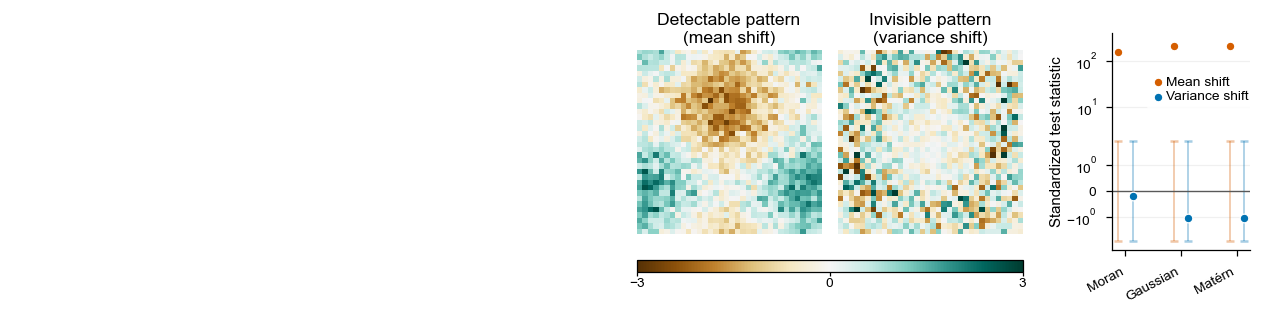

In [5]:
fig = manuscript_figure(42)
grid = fig.add_gridspec(
    1,
    2,
    left=0.035,
    right=0.97,
    bottom=0.10,
    top=0.90,
    width_ratios=(230, 245),
    wspace=0.06,
)
draw_framework_panel_a(fig, grid[0, 0])
draw_detectability_panel_b(fig, grid[0, 1])
preview_figure(fig, "Figure 1, row 1")

### Panels C-D: functional decomposition and kernel spectrum


In [6]:
def draw_spectral_framework_row(fig: plt.Figure, spec) -> None:
    """Align a dense Matérn expansion, kernel spectrum, modes, and pathologies."""
    expansion = _spectral_expansion_data()

    rows = spec.subgridspec(2, 1, height_ratios=(1, 1), hspace=0.5)
    top = rows[0].subgridspec(1, 2, width_ratios=(3, 1.5), wspace=0.2)
    decomposition = top[0].subgridspec(1, 2, width_ratios=(0.72, 2.28), wspace=0.16)
    bottom = rows[1].subgridspec(1, 2, width_ratios=(3, 1.5), wspace=0.2)
    basis_grid = bottom[0].subgridspec(1, 6, wspace=0.08)

    # Observed spatial pattern and its sampled values at graph nodes
    ax_field = fig.add_subplot(decomposition[0])
    ax_field.set_anchor("W")
    field = np.asarray(expansion["field"])
    spatial_norm = mcolors.Normalize(vmin=field.min(), vmax=field.max())
    image = ax_field.imshow(
        field,
        origin="lower",
        cmap="BrBG",
        norm=spatial_norm,
        interpolation="nearest",
    )
    samples = np.asarray(expansion["sample_coordinates"])
    ax_field.scatter(
        samples[:, 0] * (field.shape[1] - 1),
        samples[:, 1] * (field.shape[0] - 1),
        c=expansion["sample_values"],
        cmap="BrBG",
        norm=image.norm,
        s=5,
        edgecolor="black",
        linewidth=0.5,
        alpha=0.85,
    )
    ax_field.set_title(
        r"Every observed pattern has an exact harmonic expansion "
        r"$f=\sum_i\hat f_i\phi_i$",
        pad=2,
        ha="left",
        y=1.08,
    )
    ax_field.set_axis_off()

    ax_function = fig.add_subplot(decomposition[1])
    ax_kernel = fig.add_subplot(top[1])
    display_modes = int(expansion["display_modes"])
    modes = np.arange(display_modes)
    function_coefficients = np.asarray(expansion["function_coefficients"])
    kernel_spectrum = np.asarray(expansion["kernel_spectrum"])
    basis_positions = np.rint(np.linspace(1, display_modes - 1, 6)).astype(int)

    ax_function.bar(
        modes,
        function_coefficients[:display_modes],
        color=PAPER_COLORS["green"],
        width=0.8,
        alpha=0.85,
    )
    ax_function.axhline(0, color="0.3", lw=0.55)

    ax_kernel.bar(
        modes,
        kernel_spectrum[:display_modes],
        color=PAPER_COLORS["purple"],
        width=0.8,
        alpha=0.85,
    )
    ax_kernel.axhline(0, color="0.3", lw=0.55)

    for position in basis_positions:
        ax_function.axvline(position, color="0.15", ls="--", lw=0.65, alpha=0.7)
        ax_function.scatter(position, function_coefficients[position], s=10, color="0.15", zorder=3)
    pathology_styles = (
        (expansion["pathology_positions"]["positive"], PAPER_COLORS["green"]),
        (expansion["pathology_positions"]["zero"], "0.35"),
        (expansion["pathology_positions"]["negative"], PAPER_COLORS["warm"]),
    )
    for position, color in pathology_styles:
        value = kernel_spectrum[position]
        ax_kernel.axvline(position, color=color, ls="--", lw=0.7, alpha=0.8)
        ax_kernel.scatter(position, value, s=12, color=color, zorder=3)

    for ax in (ax_function, ax_kernel):
        ax.set_xlim(-1, display_modes)
        ax.set_xlabel("Eigenmode index", labelpad=0)
        ax.grid(axis="y", alpha=0.15)

    ax_function.set_ylabel(
        r"Coefficient $\hat f_i$",
        labelpad=1,
        fontsize=5.5,
    )
    ax_function.set_ylim(-1.05, 1.15)
    ax_kernel.set_ylabel(
        r"Weight $\lambda_i$",
        labelpad=1,
        fontsize=5.5,
    )
    ax_kernel.set_ylim(-1.05, 1.05)
    ax_kernel.set_title(
        "Kernel spectrum defines test preferences",
        pad=2,
        y=1.08,
    )

    for column, position in enumerate(basis_positions):
        nx, ny = expansion["display_coordinates"][position]
        values = _dct_mode(nx, ny, field.shape)
        ax = fig.add_subplot(basis_grid[column])
        ax.imshow(
            2 * values / np.max(np.abs(values)),
            origin="lower",
            cmap="coolwarm",
            vmin=-2,
            vmax=2,
            interpolation="nearest",
        )
        ax.text(
            0.5,
            0.85,
            rf"${function_coefficients[position]:+.2f}\,\phi_{{({nx},{ny})}}$",
            transform=ax.transAxes,
            ha="center",
            va="center",
            color="0.15",
            fontsize=5.5,
            bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "none", "alpha": 0.82},
        )
        ax.set_axis_off()
        ax.set_anchor("W")

    ax_pathology = fig.add_subplot(bottom[1])
    ax_pathology.axis("off")
    ax_pathology.set_title("Q-tests with non-PSD kernels are inconsistent", pad=2, y=0.78)
    ax_pathology.add_patch(
        mpl.patches.FancyBboxPatch(
            (0.01, -0.02),
            0.98,
            1.00,
            transform=ax_pathology.transAxes,
            boxstyle="round,pad=0.02",
            facecolor="#faebea",
            edgecolor="#b9a3c9",
            linewidth=0.6,
            clip_on=False,
            zorder=0,
        )
    )

    callouts = (
        (
            0.25,
            "Blind spot",
            r"$\phi_j\ with \; \lambda_j=0"
            r"\ \rightarrow\ Q(\phi_j)=0$",
            "Completely invisible pattern",
        ),
        (
            0.75,
            "Cancellation",
            r"$\lambda_p a_p^2+\lambda_n a_n^2=0$",
            "Positive and negative modes\ncan cancel exactly",
        ),
    )
    for x, title, equation, explanation in callouts:
        ax_pathology.text(
            x,
            0.65,
            title,
            transform=ax_pathology.transAxes,
            ha="center",
            va="center",
            fontsize=6,
            fontweight="semibold",
        )
        ax_pathology.text(
            x,
            0.45,
            equation,
            transform=ax_pathology.transAxes,
            ha="center",
            va="center",
            fontsize=5.5,
            color="black",
        )
        ax_pathology.text(
            x,
            0.15,
            explanation,
            transform=ax_pathology.transAxes,
            ha="center",
            va="center",
            fontsize=5.5,
            linespacing=1.25,
            bbox={
                "boxstyle": "round,pad=0.35",
                "fc": "#f7f7f7",
                "ec": "0.75",
                "lw": 0.5,
            },
        )

Figure 1, row 2


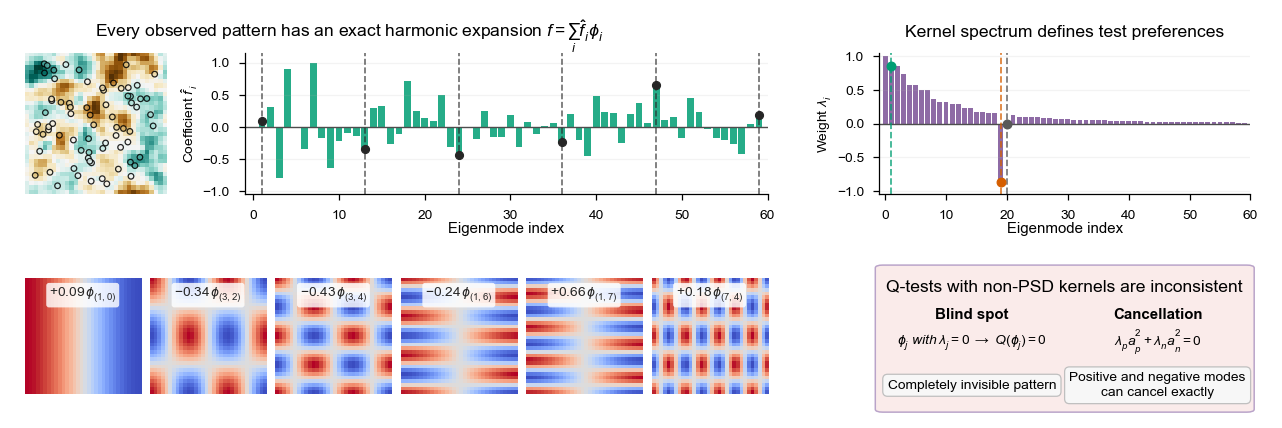

In [7]:
fig = manuscript_figure(58)
grid = fig.add_gridspec(1, 1, left=0.035, right=0.97, bottom=0.07, top=0.93)
draw_spectral_framework_row(fig, grid[0])
preview_figure(fig, "Figure 1, row 2")

### Panels E-F: practical Moran cancellation and low/high-frequency split


In [8]:
def _operator_comparison_data() -> dict[str, object]:
    size = 32
    axis = np.linspace(0, 1, size, endpoint=False)
    x, y = np.meshgrid(axis, axis)
    kx, ky = np.meshgrid(np.fft.fftfreq(size, d=1 / size), np.fft.fftfreq(size, d=1 / size))
    omega = 2 * np.pi * np.sqrt(kx**2 + ky**2)

    dx = np.minimum(np.abs(x - 0.5), 1 - np.abs(x - 0.5))
    dy = np.minimum(np.abs(y - 0.5), 1 - np.abs(y - 0.5))
    center = size // 2
    moran_kernel = (np.sqrt(dx**2 + dy**2) < 0.15).astype(float)
    moran_kernel[center, center] = 0
    moran_spectrum = np.fft.fft2(np.fft.fftshift(moran_kernel)).real

    laplacian_kernel = np.zeros((size, size))
    laplacian_kernel[center, center] = 1
    laplacian_kernel[center + 1, center] = -0.25
    laplacian_kernel[center - 1, center] = -0.25
    laplacian_kernel[center, center + 1] = -0.25
    laplacian_kernel[center, center - 1] = -0.25
    laplacian_spectrum = np.fft.fft2(np.fft.fftshift(laplacian_kernel)).real
    car_spectrum = 1 / (1 + 0.01 * omega**2)

    flat_moran = moran_spectrum.ravel()
    low_index = np.argsort(flat_moran)[-2]
    high_index = np.argmin(flat_moran)
    low_row, low_col = np.unravel_index(low_index, moran_spectrum.shape)
    high_row, high_col = np.unravel_index(high_index, moran_spectrum.shape)
    low_mode = np.cos(2 * np.pi * (kx[low_row, low_col] * x + ky[low_row, low_col] * y))
    high_mode = np.cos(2 * np.pi * (kx[high_row, high_col] * x + ky[high_row, high_col] * y))
    low_mode -= low_mode.mean()
    high_mode -= high_mode.mean()
    low_weight = np.sqrt(abs(flat_moran[high_index]))
    high_weight = np.sqrt(abs(flat_moran[low_index]))
    field = low_weight * low_mode + high_weight * high_mode
    field /= np.sqrt(np.mean(field**2))

    spectra = (moran_spectrum, laplacian_spectrum, car_spectrum)
    normalized_car = car_spectrum / car_spectrum.max()
    normalized_laplacian = laplacian_spectrum / laplacian_spectrum.max()
    rng = np.random.default_rng(17)
    bands = ((omega > 0) & (omega <= 18), (omega >= 32) & (omega <= 58))
    mixed_patterns = []
    mixed_scores = []
    for band in bands:
        coefficients = np.fft.fft2(rng.standard_normal((size, size))) * band
        pattern = np.fft.ifft2(coefficients).real
        pattern = (pattern - pattern.mean()) / pattern.std()
        power = np.abs(np.fft.fft2(pattern)) ** 2
        mixed_patterns.append(pattern)
        mixed_scores.append(
            (
                float(np.sum(power * normalized_car) / power.sum()),
                float(np.sum(power * normalized_laplacian) / power.sum()),
            )
        )
    selected = tuple(
        {
            "low_frequency": float(omega[low_row, low_col]),
            "low_weight": float(spectrum[low_row, low_col]),
            "high_frequency": float(omega[high_row, high_col]),
            "high_weight": float(spectrum[high_row, high_col]),
        }
        for spectrum in spectra
    )
    return {
        "omega": omega,
        "spectra": spectra,
        "field": field,
        "selected": selected,
        "mixed_patterns": tuple(mixed_patterns),
        "mixed_scores": tuple(mixed_scores),
    }


def draw_compact_q_framework_row(fig: plt.Figure, spec) -> None:
    """Show cancellation in the real Moran spectrum and its valid split."""
    data = _operator_comparison_data()
    grid = spec.subgridspec(1, 5, width_ratios=(1.3, 0.8, 0.1, 1.4, 0.8), wspace=0.35)

    # Moran's spectrum
    omega = np.asarray(data["omega"])
    order = np.argsort(omega.ravel())
    frequencies = omega.ravel()[order]
    mask = frequencies <= 60
    moran = np.asarray(data["spectra"][0]).ravel()[order]
    scale = np.max(np.abs(moran[mask]))
    moran /= scale
    selected = data["selected"][0]
    ax = fig.add_subplot(grid[0])
    ax.scatter(
        frequencies[mask],
        moran[mask],
        s=2.5,
        color="0.35",
        alpha=0.65,
        edgecolor="none",
        rasterized=True,
    )
    ax.scatter(
        (selected["low_frequency"], selected["high_frequency"]),
        (selected["low_weight"] / scale, selected["high_weight"] / scale),
        s=20,
        color=(LOW_FREQUENCY_COLOR, HIGH_FREQUENCY_COLOR),
        edgecolor="white",
        linewidth=0.5,
        zorder=3,
    )
    ax.axhline(0, color="0.45", lw=0.5, ls="--")
    ax.set_title("Moran's spectrum always has opposite modes", pad=2, ha="left", x=0.05, y=1.05)
    ax.set(
        xlabel=r"Frequency $\|\omega\|$",
        ylabel="Relative spectral weight",
        xlim=(0, 60),
    )
    ax.yaxis.labelpad = 0
    ax.grid(alpha=0.16)
    for frequency, weight, label, color, offset in (
        (
            selected["low_frequency"],
            selected["low_weight"] / scale,
            r"$\phi_L$",
            LOW_FREQUENCY_COLOR,
            (4, 4),
        ),
        (
            selected["high_frequency"],
            selected["high_weight"] / scale,
            r"$\phi_H$",
            HIGH_FREQUENCY_COLOR,
            (-1, 6),
        ),
    ):
        ax.annotate(
            label,
            (frequency, weight),
            xytext=offset,
            textcoords="offset points",
            color=color,
            fontsize=6.0,
        )

    # Heatmap of the synthetic Moran's I null
    ax = fig.add_subplot(grid[1])
    field = np.asarray(data["field"])
    ax.imshow(
        field / np.max(np.abs(field)),
        origin="lower",
        cmap="BrBG",
        vmin=-1,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_axis_off()
    # ax.set_title(r"$f=a\phi_L+b\phi_H$", pad=2, y=1.02)
    ax.text(
        0.5,
        -0.05,
        r"$f=a\phi_L+b\phi_H$" + "\n" + r"$Q_{\rm Moran}(f)=0$",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=7.0,
        bbox={"fc": "white", "ec": "none", "alpha": 0.82, "pad": 1},
    )

    # Show the two valid spectra that separate the low and high frequency bands
    ax = fig.add_subplot(grid[3])
    laplacian = np.asarray(data["spectra"][1]).ravel()[order]
    car = np.asarray(data["spectra"][2]).ravel()[order]
    laplacian /= np.max(laplacian[mask])
    car /= np.max(car[mask])
    ax.plot(
        frequencies[mask],
        car[mask],
        color=LOW_FREQUENCY_COLOR,
        lw=0.9,
        label="CAR-Q (low frequency)",
    )
    ax.plot(
        frequencies[mask],
        laplacian[mask],
        color=HIGH_FREQUENCY_COLOR,
        lw=0.9,
        label="Laplacian-Q (high frequency)",
    )
    ax.axhline(0, color="0.55", lw=0.5)
    ax.set_title(
        "PSD kernels separately target low- and high-frequency bands",
        pad=2,
        ha="left",
        x=0.05,
        y=1.05,
    )
    ax.set(
        xlabel=r"Frequency $\|\omega\|$",
        ylabel="Relative spectral weight",
        xlim=(0, 60),
        ylim=(-0.04, 1.05),
    )
    ax.legend(frameon=False, loc="upper center", handlelength=1.2)
    ax.grid(alpha=0.16)

    # Example low- and high-frequency patterns and their Q-statistics
    pattern_grid = grid[4].subgridspec(2, 1, hspace=0.2)
    for row, (pattern, scores, title) in enumerate(
        zip(
            data["mixed_patterns"],
            data["mixed_scores"],
            ("Low-frequency", "High-frequency"),
            strict=True,
        )
    ):
        ax = fig.add_subplot(pattern_grid[row])
        ax.imshow(
            pattern,
            origin="lower",
            cmap="BrBG",
            vmin=-2.5,
            vmax=2.5,
            interpolation="nearest",
        )
        ax.set_anchor("E")
        ax.set_axis_off()
        ax.text(
            -1.35,
            0.5,
            title
            + "\n"
            + rf"$Q_{{\rm CAR}}={scores[0]:.2f}$"
            + "\n"
            + rf"$Q_{{\rm Lap}}={scores[1]:.2f}$",
            transform=ax.transAxes,
            ha="left",
            va="center",
            fontsize=5.5,
            color="0.20",
            bbox={"fc": "white", "ec": "none", "alpha": 0.82, "pad": 1},
        )

Figure 1, row 3


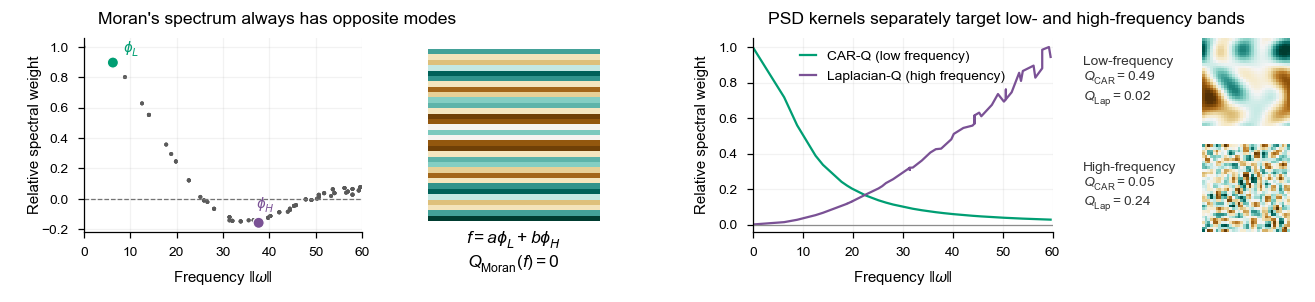

In [9]:
fig = manuscript_figure(35)
grid = fig.add_gridspec(1, 1, left=0.050, right=0.97, bottom=0.12, top=0.90)
draw_compact_q_framework_row(fig, grid[0])
preview_figure(fig, "Figure 1, row 3")

### Panel G: relational R as a weighted spectral inner product


In [10]:
def _relation_frequency_data() -> dict[str, np.ndarray | float]:
    """Return two spatial features and their mode-wise weighted association."""
    expansion = _spectral_expansion_data()
    n_modes = int(expansion["display_modes"])
    coefficients_x = np.zeros(n_modes)
    coefficients_y = np.zeros(n_modes)
    selected = np.asarray(
        (*expansion["selected_positions"]["low"], *expansion["selected_positions"]["high"]),
        dtype=int,
    )
    coefficients_x[selected] = (1.00, -0.80, 1.00, -1.00)
    coefficients_y[selected] = (0.85, -0.70, -0.75, 0.66)

    selected_coordinates = (
        *expansion["mode_coordinates"]["low"],
        *expansion["mode_coordinates"]["high"],
    )
    shape = np.asarray(expansion["field"]).shape
    values_x = sum(
        coefficient * _dct_mode(*coordinate, shape)
        for coefficient, coordinate in zip(
            coefficients_x[selected], selected_coordinates, strict=True
        )
    ).ravel()
    values_y = sum(
        coefficient * _dct_mode(*coordinate, shape)
        for coefficient, coordinate in zip(
            coefficients_y[selected], selected_coordinates, strict=True
        )
    ).ravel()

    kernel_spectrum = np.exp(-np.linspace(0, 3, n_modes))
    modal_overlap = coefficients_x * coefficients_y
    weighted_overlap = kernel_spectrum * modal_overlap
    return {
        "values_x": values_x,
        "values_y": values_y,
        "raw_correlation": float(np.corrcoef(values_x, values_y)[0, 1]),
        "coefficients_x": coefficients_x,
        "coefficients_y": coefficients_y,
        "kernel_spectrum": kernel_spectrum,
        "modal_overlap": modal_overlap,
        "weighted_overlap": weighted_overlap,
        "selected": selected,
        "score": float(weighted_overlap.sum()),
    }

In [11]:
def draw_relation_framework_row(fig: plt.Figure, spec) -> None:
    """Explain R from spatial maps to positive spectral weighting."""
    data = _relation_frequency_data()
    expansion = _spectral_expansion_data()

    selected = np.asarray(
        (
            *expansion["selected_positions"]["low"],
            *expansion["selected_positions"]["high"],
        ),
        dtype=int,
    )
    coefficients_x = np.asarray(data["coefficients_x"])
    coefficients_y = np.asarray(data["coefficients_y"])
    spectrum = np.asarray(data["kernel_spectrum"])
    weights = spectrum[selected]
    colors = (
        LOW_FREQUENCY_COLOR,
        LOW_FREQUENCY_COLOR,
        HIGH_FREQUENCY_COLOR,
        HIGH_FREQUENCY_COLOR,
    )
    labels = ("L1", "L2", "H1", "H2")

    grid = spec.subgridspec(
        1,
        8,
        width_ratios=(1.35, 0.05, 1, 0.6, 0.05, 1, 0.05, 1),
        wspace=0.3,
    )

    shape = np.asarray(expansion["field"]).shape
    values_x = np.asarray(data["values_x"])
    values_y = np.asarray(data["values_y"])
    fields = (values_x.reshape(shape), values_y.reshape(shape))
    limit = max(np.max(np.abs(field)) for field in fields)
    spatial_norm = mcolors.TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit,
    )

    spot_rows = np.rint(np.asarray((0.18, 0.52, 0.82)) * (shape[0] - 1)).astype(int)
    spot_cols = np.rint(np.asarray((0.20, 0.80, 0.48)) * (shape[1] - 1)).astype(int)
    spot_indices = spot_rows * shape[1] + spot_cols
    spot_colors = (
        PAPER_COLORS["gold"],
        PAPER_COLORS["purple"],
        PAPER_COLORS["green"],
    )
    spot_markers = ("o", "s", "D")
    spot_labels = ("A", "B", "C")

    def annotate_spots(ax, xs, ys, size: float) -> None:
        for x, y, color, marker, label in zip(
            xs,
            ys,
            spot_colors,
            spot_markers,
            spot_labels,
            strict=True,
        ):
            ax.scatter(
                x,
                y,
                s=size,
                marker=marker,
                color=color,
                edgecolor="white",
                linewidth=0.5,
                zorder=3,
            )
            ax.annotate(
                label,
                (x, y),
                xytext=(3, 3),
                textcoords="offset points",
                fontsize=5.5,
                color=color,
                fontweight="bold",
            )

    def annotate_modes(ax, xs, ys, offsets) -> None:
        for x, y, label, color, offset in zip(
            xs,
            ys,
            labels,
            colors,
            offsets,
            strict=True,
        ):
            ax.annotate(
                label,
                (x, y),
                xytext=offset,
                textcoords="offset points",
                fontsize=5.5,
                color=color,
            )

    heatmap_grid = grid[0].subgridspec(
        2,
        2,
        height_ratios=(1, 0.08),
        hspace=0.1,
        wspace=0.08,
    )
    heatmap_axes = [fig.add_subplot(heatmap_grid[0, column]) for column in range(2)]

    image = None
    for ax, field, label in zip(
        heatmap_axes,
        fields,
        (r"$z_x(s)$", r"$z_y(s)$"),
        strict=True,
    ):
        image = ax.imshow(
            field,
            origin="lower",
            cmap="BrBG",
            norm=spatial_norm,
            interpolation="nearest",
            rasterized=True,
        )
        annotate_spots(ax, spot_cols, spot_rows, 16)
        ax.set_title(label, pad=1, y=-0.15)
        ax.set_box_aspect(1)
        ax.set_anchor("N")
        ax.set_axis_off()

    colorbar = fig.colorbar(
        image,
        cax=fig.add_subplot(heatmap_grid[1, :]),
        orientation="horizontal",
    )
    colorbar.set_ticks((-limit, 0, limit))
    colorbar.ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f"))
    colorbar.ax.tick_params(labelsize=5.5, length=1.8, pad=1)

    ax_raw = fig.add_subplot(grid[2])
    ax_raw.scatter(
        values_x,
        values_y,
        s=2,
        color="0.35",
        alpha=0.28,
        edgecolor="none",
        rasterized=True,
    )
    annotate_spots(
        ax_raw,
        values_x[spot_indices],
        values_y[spot_indices],
        24,
    )

    raw_limit = max(
        np.max(np.abs(values_x)),
        np.max(np.abs(values_y)),
    )
    ax_raw.axhline(0, color="0.75", lw=0.5)
    ax_raw.axvline(0, color="0.75", lw=0.5)
    ax_raw.set_xlabel(r"$z_x(s)$", labelpad=1)
    ax_raw.set_ylabel(r"$z_y(s)$", labelpad=1)
    ax_raw.set(
        xlim=(-raw_limit, raw_limit),
        ylim=(-raw_limit, raw_limit),
        xticks=(-0.2, 0, 0.2),
        yticks=(-0.2, 0, 0.2),
    )
    ax_raw.text(
        0.05,
        0.98,
        rf"Pearson $r={data['raw_correlation']:.2f}$",
        transform=ax_raw.transAxes,
        ha="left",
        va="top",
        fontsize=5.5,
    )
    ax_raw.set_title(
        "Co-expression in the spatial domain",
        ha="right",
        x=0.3,
        pad=2,
        y=1.05,
    )

    ax_transform = fig.add_subplot(grid[3])
    ax_transform.axis("off")
    ax_transform.text(
        0.5,
        0.68,
        "Spectral transform",
        transform=ax_transform.transAxes,
        ha="center",
        va="center",
        fontsize=6,
    )
    ax_transform.annotate(
        "",
        xy=(0.9, 0.52),
        xytext=(0.1, 0.52),
        xycoords="axes fraction",
        arrowprops={
            "arrowstyle": "-|>",
            "lw": 0.7,
            "color": "0.35",
        },
    )
    ax_transform.text(
        0.5,
        0.32,
        r"$z_x^{\mathrm{T}}z_y=\sum_i a_i b_i$",
        transform=ax_transform.transAxes,
        ha="center",
        va="center",
        fontsize=5.5,
    )

    ax_modes = fig.add_subplot(grid[5])
    mode_limit = 1.12
    for xy, color in (
        ((0, 0), LOW_FREQUENCY_COLOR),
        ((-mode_limit, -mode_limit), LOW_FREQUENCY_COLOR),
        ((-mode_limit, 0), HIGH_FREQUENCY_COLOR),
        ((0, -mode_limit), HIGH_FREQUENCY_COLOR),
    ):
        ax_modes.add_patch(
            mpl.patches.Rectangle(
                xy,
                mode_limit,
                mode_limit,
                facecolor=color,
                alpha=0.055,
                edgecolor="none",
            )
        )

    ax_modes.axhline(0, color="0.7", lw=0.5)
    ax_modes.axvline(0, color="0.7", lw=0.5)
    ax_modes.axline(
        (0, 0),
        slope=1,
        color="0.65",
        lw=0.5,
        ls="--",
    )
    ax_modes.scatter(
        coefficients_x[selected],
        coefficients_y[selected],
        s=18,
        color=colors,
        edgecolor="white",
        linewidth=0.5,
        zorder=3,
    )
    annotate_modes(
        ax_modes,
        coefficients_x[selected],
        coefficients_y[selected],
        ((3, 3), (3, 3), (-18, 3), (3, 3)),
    )

    for x, y, text, color in (
        (0.28, 0.65, "Opposite signs", HIGH_FREQUENCY_COLOR),
        (0.72, 0.8, "Same sign", LOW_FREQUENCY_COLOR),
    ):
        ax_modes.text(
            x,
            y,
            text,
            transform=ax_modes.transAxes,
            ha="center",
            va="center",
            color=color,
            fontsize=5.5,
            bbox={
                "fc": "white",
                "ec": "none",
                "alpha": 0.65,
                "pad": 0.6,
            },
        )

    ax_modes.text(
        0.5,
        0.51,
        "(inactive modes ignored)",
        transform=ax_modes.transAxes,
        ha="center",
        va="center",
        fontsize=5.5,
        color="0.35",
        bbox={
            "fc": "white",
            "ec": "none",
            "alpha": 0.8,
            "pad": 0.8,
        },
    )
    ax_modes.set_xlabel(r"$a_i$", labelpad=1)
    ax_modes.set_ylabel(r"$b_i$", labelpad=1)
    ax_modes.set(
        xlim=(-mode_limit, mode_limit),
        ylim=(-mode_limit, mode_limit),
        xticks=(-1, 0, 1),
        yticks=(-1, 0, 1),
    )

    ax_kernel = fig.add_subplot(grid[7])
    all_modes = np.arange(len(spectrum))
    ax_kernel.fill_between(
        all_modes,
        0,
        spectrum,
        color="0.72",
        alpha=0.18,
        linewidth=0,
    )
    ax_kernel.plot(all_modes, spectrum, color="0.62", lw=0.7)
    ax_kernel.vlines(
        selected,
        0,
        weights,
        colors=colors,
        lw=1.2,
        zorder=2,
    )
    ax_kernel.scatter(
        selected,
        weights,
        color=colors,
        s=18,
        edgecolor="white",
        linewidth=0.5,
        zorder=3,
    )
    annotate_modes(
        ax_kernel,
        selected,
        weights,
        ((3, 4), (3, -9), (3, 4), (3, -9)),
    )

    ax_kernel.axhline(0, color="0.35", lw=0.5)
    ax_kernel.set(
        xlabel="Mode index",
        ylabel=r"$\lambda_i$",
        xlim=(-1, len(spectrum)),
        ylim=(0, 1.08),
    )
    ax_kernel.grid(axis="y", alpha=0.16)
    ax_kernel.text(
        0.97,
        0.95,
        rf"$R_K=\sum_i \lambda_i a_i b_i = {data['score']:.2f}$",
        transform=ax_kernel.transAxes,
        ha="right",
        va="top",
        fontsize=5.5,
        linespacing=1.2,
        bbox={
            "fc": "white",
            "ec": "0.75",
            "lw": 0.5,
            "pad": 1,
        },
    )
    ax_kernel.set_title(
        "Co-localization in the spectral domain",
        ha="right",
        x=0.5,
        pad=2,
        y=1.05,
    )

    for ax in (ax_raw, ax_modes, ax_kernel):
        ax.set_box_aspect(1)
        # ax.set_anchor("N")

Figure 1, row 4


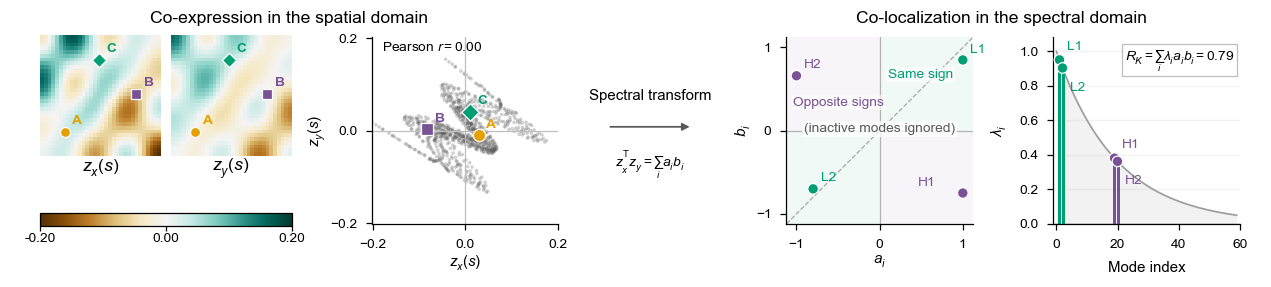

In [12]:
fig = manuscript_figure(35)
grid = fig.add_gridspec(1, 1, left=0.055, right=0.97, bottom=0.18, top=0.95)
draw_relation_framework_row(fig, grid[0])
preview_figure(fig, "Figure 1, row 4")

### Preview and save the combined Figure 1


Combined Figure 1


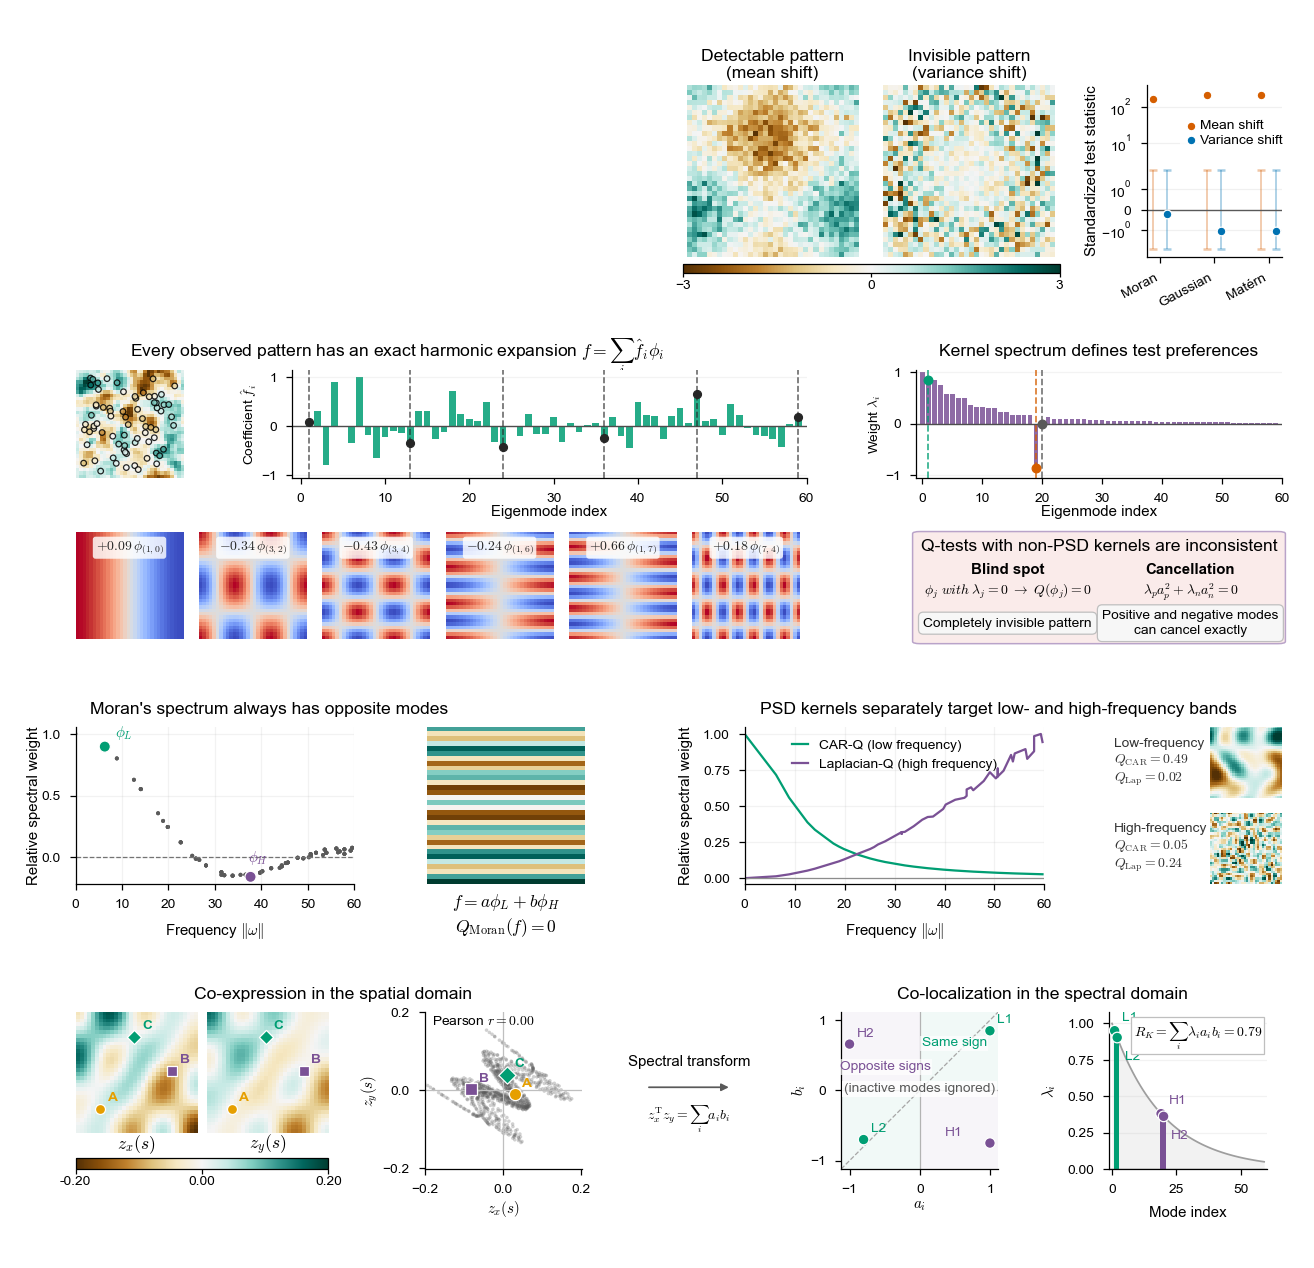

In [13]:
def build_framework_figure() -> plt.Figure:
    fig = manuscript_figure(170)
    outer = fig.add_gridspec(
        7,
        1,
        left=0.050,
        right=0.97,
        bottom=0.050,
        top=0.950,
        hspace=0.3,
        height_ratios=(0.42, 0.05, 0.6, 0.03, 0.35, 0.12, 0.35),
    )
    row1 = outer[0].subgridspec(1, 2, width_ratios=(230, 241), wspace=0.06)
    draw_framework_panel_a(fig, row1[0, 0])
    draw_detectability_panel_b(fig, row1[0, 1])
    draw_spectral_framework_row(fig, outer[2])
    draw_compact_q_framework_row(fig, outer[4])
    draw_relation_framework_row(fig, outer[6])
    return fig


with mpl.rc_context(COMPUTER_MODERN_MATHTEXT):
    preview_figure(build_framework_figure(), "Combined Figure 1")

In [14]:
with mpl.rc_context(COMPUTER_MODERN_MATHTEXT):
    save_figure(build_framework_figure(), FRAMEWORK_FIGURE_FILE)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


main_framework.pdf


## Main Figure 2: runtime and kernel prioritization


In [15]:
# Figure 2 configuration
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

from .config import (
    ARTIFACT_GENES,
    BENCHMARK_PROJECTION_FILE,
    BENCHMARK_SCALING_FILE,
    FAST_DECAY_RHO,
    IMMUNE_GENES,
    M_FEATURES,
    PIXEL_SIZE_UM,
    RUNTIME_MEMORY_BUDGET_MB,
    SLOW_DECAY_RHO,
    SMALL_INTESTINE_PATTERN_RANKS_FILE,
    SMALL_INTESTINE_SCORES_FILE,
)
from .small_intestine import load_gene_maps, radial_profile, rho_key

IMPL_COLORS = {
    "Matrix-Matern (dense)": PAPER_COLORS["cool"],
    "Matrix-CAR (sparse)": PAPER_COLORS["purple"],
    "Matrix-Moran (sparse)": PAPER_COLORS["green"],
    "FFT-Matern": PAPER_COLORS["gold"],
    "NUFFT-Matern": PAPER_COLORS["warm"],
}
PATTERN_COLORS = {
    "Swiss-roll artifact": PAPER_COLORS["warm"],
    "Immune cluster": PAPER_COLORS["cool"],
}

# Load the small intestine gene maps and associated data
small_intestine_maps, small_intestine_mask, small_intestine_genes = load_gene_maps(SOURCE)

/Users/jysumac/Projects/sonic-paper/scripts/qtest_benchmark/small_intestine.py:53: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  table = sd.read_zarr(source).tables["square_016um"]


### Row 1: runtime and memory benchmark


In [16]:
def _format_runtime(seconds: float) -> str:
    if seconds < 1:
        return "<1 s"
    if seconds < 60:
        return f"{seconds:.2g} s"
    if seconds < 3600:
        return f"{seconds / 60:.2g} min"
    return f"{seconds / 3600:.2g} h"


def _plot_scaling(ax, benchmark: pd.DataFrame, column: str, ylabel: str) -> None:
    clean = benchmark.dropna(subset=["n", column])
    for impl, color in IMPL_COLORS.items():
        sub = clean[clean["impl"].eq(impl)].sort_values("n")
        if not sub.empty:
            label = impl.replace("Matrix-", "").replace("-Matern", " Matern")
            ax.loglog(sub["n"], sub[column], "o-", color=color, lw=1.0, ms=2.5, label=label)
    ax.set_xlabel("Number of samples $n$")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", alpha=0.22)


def _plot_projection(ax, projection: pd.DataFrame) -> None:
    targets = projection["target"].drop_duplicates().tolist()
    impls = list(IMPL_COLORS)
    width = 0.8 / len(impls)
    y_floor = 0.5
    for i, impl in enumerate(impls):
        values = []
        for target in targets:
            row = projection[projection["impl"].eq(impl) & projection["target"].eq(target)]
            if len(row) != 1:
                raise ValueError(
                    f"Expected one projection row for {impl!r}, {target!r}; found {len(row)}"
                )
            record = row.iloc[0]
            values.append(float(record["total_s"]) if record["supported"] else np.nan)
        positions = np.arange(len(targets)) + (i - (len(impls) - 1) / 2) * width
        ax.bar(positions, values, width=width * 0.94, color=IMPL_COLORS[impl], label=impl)
        for x, value in zip(positions, values, strict=True):
            if np.isnan(value):
                ax.plot(
                    x,
                    y_floor,
                    "x",
                    color=IMPL_COLORS[impl],
                    ms=4,
                    mew=1.0,
                    clip_on=False,
                )
            else:
                ax.text(
                    x,
                    value * 1.12 + y_floor,
                    _format_runtime(value),
                    rotation=90,
                    ha="center",
                    va="bottom",
                    fontsize=FONT_CONFIG["text"],
                    color=IMPL_COLORS[impl],
                )
    target_n = projection.drop_duplicates("target").set_index("target")["n"]
    target_labels = []
    for name in targets:
        n = target_n[name]
        short_n = f"{n / 1e6:g}M" if n >= 1e6 else f"{n / 1e3:g}K"
        short_name = name.replace(" 16µm", "\n16 µm").replace(" 2µm", "\n2 µm")
        target_labels.append(f"{short_name}\n{short_n}")
    ax.set_yscale("log")
    ax.set_xticks(np.arange(len(targets)))
    ax.set_xticklabels(target_labels, fontsize=FONT_CONFIG["text"])
    ax.set_ylabel(f"Projected runtime (s)\nfor {M_FEATURES:,} features")
    for threshold, label in ((60, "1 min"), (3600, "1 h")):
        ax.axhline(threshold, color="0.45", ls=":", lw=0.8)
        ax.text(
            0.02,
            threshold,
            label,
            transform=ax.get_yaxis_transform(),
            ha="left",
            va="bottom",
            fontsize=FONT_CONFIG["text"],
            color="0.35",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.3},
        )
    ax.grid(True, which="major", axis="y", alpha=0.2)
    finite = projection["total_s"].dropna()
    if finite.empty:
        raise ValueError("Projection cache contains no supported runtime")
    ax.set_ylim(y_floor, max(10.0, finite.max() * 7))


def draw_runtime_benchmark_panel(
    fig: plt.Figure, spec, benchmark: pd.DataFrame, projection: pd.DataFrame
) -> None:
    """Draw the grouped single-call benchmarks and transcriptome projection."""
    top = spec.subgridspec(1, 2, wspace=0.24, width_ratios=(2.0, 1.0))
    single_call = top[0, 0].subgridspec(1, 2, wspace=0.34)
    ax_time = fig.add_subplot(single_call[0, 0])
    ax_memory = fig.add_subplot(single_call[0, 1])
    ax_projection = fig.add_subplot(top[0, 1])
    _plot_scaling(ax_time, benchmark, "single_call_s", "Wall time (s)")
    ax_time.set_title("Single-call time", y=1.05)
    _plot_scaling(ax_memory, benchmark, "peak_mb", "Peak memory (MB)")
    ax_memory.set_title("Single-call memory", y=1.05)
    handles, labels = ax_time.get_legend_handles_labels()
    row_box = spec.get_position(fig)
    fig.legend(
        handles,
        labels,
        loc="center",
        bbox_to_anchor=((row_box.x0 + row_box.x1) / 2, row_box.y0 - 0.12),
        ncol=len(labels),
        frameon=False,
        columnspacing=1.0,
        handlelength=1.5,
        handletextpad=0.4,
    )
    _plot_projection(ax_projection, projection)
    ax_projection.set_title(
        f"Transcriptome-wide time (1 core, {RUNTIME_MEMORY_BUDGET_MB / 1000:g} GB RAM)",
        y=1.05,
    )

Runtime and memory benchmark


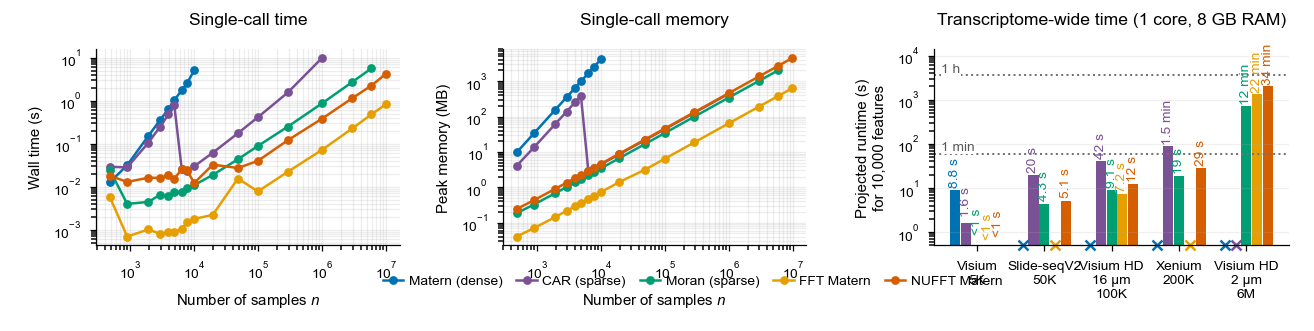

In [17]:
fig = manuscript_figure(42)
grid = fig.add_gridspec(1, 1, left=0.06, right=0.97, bottom=0.22, top=0.88)
draw_runtime_benchmark_panel(
    fig,
    grid[0],
    pd.read_csv(BENCHMARK_SCALING_FILE),
    pd.read_csv(BENCHMARK_PROJECTION_FILE),
)
preview_figure(fig, "Runtime and memory benchmark")

### Row 2: small-intestine kernel prioritization


In [18]:
def _transparent_cmap(name: str):
    colors = plt.get_cmap(name)(np.linspace(0, 1, 256))
    cmap = mcolors.LinearSegmentedColormap.from_list(f"{name}_transparent", colors)
    cmap.set_under((1, 1, 1, 0))
    cmap.set_bad((1, 1, 1, 0))
    return cmap


def _plot_pattern_maps(ax, maps: np.ndarray, mask: np.ndarray, genes: list[str]) -> None:
    """Visualizing two selected genes as spatial heatmaps."""
    reg3b = np.ma.masked_where(
        ~mask | (maps[genes.index("Reg3b")] < 10), maps[genes.index("Reg3b")]
    )
    coro1a = np.ma.masked_where(
        ~mask | (maps[genes.index("Coro1a")] < 1), maps[genes.index("Coro1a")]
    )
    reg3b_image = ax.imshow(
        reg3b,
        cmap=_transparent_cmap("Oranges"),
        norm=LogNorm(vmin=10, vmax=400),
        interpolation="nearest",
    )
    coro1a_image = ax.imshow(
        coro1a,
        cmap=_transparent_cmap("Blues"),
        norm=LogNorm(vmin=1, vmax=10),
        alpha=0.72,
        interpolation="nearest",
    )
    for image, bounds, ticks, label in (
        (reg3b_image, [0.82, 0.93, 0.17, 0.022], [10, 400], "Reg3b"),
        (coro1a_image, [0.82, 0.73, 0.17, 0.022], [1, 10], "Coro1a"),
    ):
        color_ax = ax.inset_axes(bounds)
        colorbar = ax.figure.colorbar(
            image,
            cax=color_ax,
            orientation="horizontal",
            ticks=ticks,
            format=mpl.ticker.FormatStrFormatter("%g"),
        )
        colorbar.minorticks_off()
        colorbar.ax.tick_params(labelsize=FONT_CONFIG["text"], length=1.5, pad=1)
        colorbar.ax.set_title(label, fontsize=FONT_CONFIG["text"], fontstyle="italic", pad=0.5)
    ax.set_title("Spatial artifact /\nImmune cluster")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.add_artist(
        AnchoredSizeBar(
            ax.transData,
            1000 / PIXEL_SIZE_UM,
            "1 mm",
            loc="lower left",
            pad=0.3,
            borderpad=0.5,
            sep=2,
            frameon=False,
            size_vertical=2,
            color="0.15",
            fontproperties={"size": FONT_CONFIG["text"]},
        )
    )


def _plot_hyperparameter_scatter(ax, scatter: pd.DataFrame) -> None:
    """Scatter plot of gene Q-scores for two different CAR hyperparameters."""
    x_col = f"Z_{rho_key(SLOW_DECAY_RHO)}"
    y_col = f"Z_{rho_key(FAST_DECAY_RHO)}"
    ax.scatter(
        scatter[x_col],
        scatter[y_col],
        color="0.72",
        alpha=0.25,
        s=3,
        edgecolors="none",
        rasterized=True,
    )
    for group, genes in (
        ("Swiss-roll artifact", ARTIFACT_GENES),
        ("Immune cluster", IMMUNE_GENES),
    ):
        sub = scatter[scatter["gene"].isin(genes)]
        ax.scatter(
            sub[x_col],
            sub[y_col],
            color=PATTERN_COLORS[group],
            s=12,
            label=group,
            zorder=3,
        )

    label_genes = ARTIFACT_GENES + IMMUNE_GENES
    annotated = scatter.set_index("gene").loc[list(label_genes)]
    target_x = annotated[x_col].to_numpy()
    target_y = annotated[y_col].to_numpy()
    texts = [
        ax.text(x, y, gene, fontsize=FONT_CONFIG["text"], fontstyle="italic")
        for gene, x, y in zip(label_genes, target_x, target_y, strict=True)
    ]

    highlighted = scatter[scatter["gene"].isin(label_genes)]
    upper = max(
        float(scatter[[x_col, y_col]].quantile(0.998).max()),
        float(highlighted[[x_col, y_col]].max().max()) * 1.08,
    )
    lower = min(0.0, float(scatter[[x_col, y_col]].quantile(0.002).min()))
    ax.plot([lower, upper], [lower, upper], color="0.4", lw=0.6, alpha=0.5)
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    adjust_text(
        texts,
        target_x=target_x,
        target_y=target_y,
        ax=ax,
        expand=(1.15, 1.25),
        force_text=(0.25, 0.35),
        force_static=(0.15, 0.25),
        force_pull=(0.02, 0.02),
        max_move=(8, 8),
        min_arrow_len=3,
        iter_lim=500,
        arrowprops={"arrowstyle": "-", "color": "0.4", "lw": 0.4},
    )
    ax.set_xlabel(rf"Z-score, $\rho={SLOW_DECAY_RHO:.2f}$ (slow decay)")
    ax.set_ylabel(rf"Z-score, $\rho={FAST_DECAY_RHO:.2f}$ (fast decay)")
    ax.set_title("Different kernels prioritize\ndifferent spatial patterns")
    ax.grid(True, alpha=0.16)


def _gene_radial_profile(image: np.ndarray, mask: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Retain the notebook's normalized azimuthal FFT profile."""
    values = image.astype(float).copy()
    values[~mask] = 0.0
    values = (values - values.mean()) / (values.std() + 1e-10)
    frequency, profile = radial_profile(np.abs(np.fft.fft2(values)) ** 2)
    profile /= profile.sum() + np.finfo(float).eps
    valid = (frequency > 0) & (profile > 0)
    return frequency[valid], profile[valid]


def _car_theoretical_profile(frequency: np.ndarray, rho: float) -> np.ndarray:
    """Evaluate the continuum CAR spectrum on a radial frequency grid."""
    alpha = rho * (np.pi * PIXEL_SIZE_UM) ** 2 / (1.0 - rho)
    weight = 1.0 / (1.0 + alpha * frequency**2)
    return weight / weight.sum()


def _plot_radial_profiles(ax, maps: np.ndarray, mask: np.ndarray, genes: list[str]) -> None:
    """Radial power spectra for two selected gene groups and two CAR kernels."""
    for group, gene_group in (
        ("Swiss-roll artifact", ARTIFACT_GENES),
        ("Immune cluster", IMMUNE_GENES),
    ):
        color = PATTERN_COLORS[group]
        curves = []
        for gene in gene_group:
            frequency, profile = _gene_radial_profile(maps[genes.index(gene)], mask)
            curves.append(profile)
            ax.loglog(frequency, profile, color=color, alpha=0.16, lw=0.5)
        mean_profile = np.mean(np.stack(curves), axis=0)
        ax.loglog(
            frequency,
            mean_profile,
            color=color,
            lw=1.3,
            label="Artifact" if group == "Swiss-roll artifact" else "Immune",
        )

    for rho, color, linestyle in (
        (SLOW_DECAY_RHO, PAPER_COLORS["charcoal"], "--"),
        (FAST_DECAY_RHO, PAPER_COLORS["neutral"], ":"),
    ):
        ax.loglog(
            frequency,
            _car_theoretical_profile(frequency, rho),
            linestyle,
            color=color,
            lw=1.0,
            label=rf"CAR $\rho={rho:.2f}$",
        )

    ax.set_xlabel("Spatial frequency (1/µm)")
    ax.set_ylabel("Normalized power / weights")
    ax.set_ylim(1e-6, 1.1)
    ax.set_title("Hyperparameter controls pattern\nselectivity via kernel spectrum")
    ax.grid(True, which="both", alpha=0.14)
    ax.legend(
        frameon=False,
        loc="lower left",
        ncol=2,
        columnspacing=0.6,
        handlelength=1.5,
        handletextpad=0.4,
    )


def _plot_pattern_ranks(ax, priority: pd.DataFrame) -> None:
    car_rhos = sorted(
        float(key.removeprefix("rho_"))
        for key in priority["kernel"].unique()
        if key.startswith("rho_")
    )
    kernels = [rho_key(rho) for rho in car_rhos] + ["fit_artifact", "fit_immune"]
    positions = {kernel: index for index, kernel in enumerate(kernels[: len(car_rhos)])}
    positions.update({"fit_artifact": len(car_rhos) + 1, "fit_immune": len(car_rhos) + 2})
    for group in ("Swiss-roll artifact", "Immune cluster"):
        sub = priority[priority["group"].eq(group)].set_index("kernel").loc[kernels]
        x = np.asarray([positions[kernel] for kernel in kernels])
        y = sub["median_transcriptome_rank"].to_numpy()
        color = PATTERN_COLORS[group]
        ax.plot(x[: len(car_rhos)], y[: len(car_rhos)], "o-", color=color, lw=1.1, ms=2.5)
        ax.scatter(
            x[len(car_rhos) :],
            y[len(car_rhos) :],
            color=color,
            marker="D",
            s=11,
            zorder=3,
        )

    for row, (group, kernel) in enumerate(
        (("Swiss-roll artifact", "fit_artifact"), ("Immune cluster", "fit_immune"))
    ):
        fit = priority[priority["group"].eq(group) & priority["kernel"].eq(kernel)].iloc[0]
        ax.text(
            0.03,
            0.18 + 0.08 * row,
            f"{group.replace(' cluster', '').replace('Swiss-roll ', '').title()} fit: "
            f"{fit['fit_seconds'] * 1000:.0f} ms · {fit['spectral_storage_mb']:.1f} MB",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=FONT_CONFIG["text"],
            color=PATTERN_COLORS[group],
        )

    fit_start = len(car_rhos) + 0.5
    ax.axvspan(fit_start, len(car_rhos) + 2.5, color=PAPER_COLORS["purple"], alpha=0.07, zorder=0)
    ax.axvline(fit_start, color="0.45", lw=0.8)
    ax.set_xticks([positions[kernel] for kernel in kernels])
    ax.set_xticklabels([f"{rho:.2f}".lstrip("0") for rho in car_rhos] + ["A", "I"])
    for tick, color in zip(
        ax.get_xticklabels()[-2:],
        (PATTERN_COLORS["Swiss-roll artifact"], PATTERN_COLORS["Immune cluster"]),
        strict=True,
    ):
        tick.set_color(color)
        tick.set_fontweight("bold")
    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_xlabel(r"CAR $\rho$ / spectral fit")
    ax.set_ylabel("Median transcriptome rank\n(1 = best)")
    ax.set_title(
        "Near-arbitrary gene ordering\nvia spectral kernel fitting",
    )
    ax.grid(True, axis="y", which="both", alpha=0.18)


def draw_small_intestine_panel(
    fig: plt.Figure,
    spec,
    scatter: pd.DataFrame,
    priority: pd.DataFrame,
    maps: np.ndarray,
    mask: np.ndarray,
    genes: list[str],
) -> None:
    """Draw the four small-intestine kernel-prioritization axes."""
    bottom = spec.subgridspec(1, 4, wspace=0.60)
    ax_map = fig.add_subplot(bottom[0, 0])
    ax_priority = fig.add_subplot(bottom[0, 1])
    ax_profiles = fig.add_subplot(bottom[0, 2])
    ax_ranks = fig.add_subplot(bottom[0, 3])
    _plot_pattern_maps(ax_map, maps, mask, genes)
    _plot_hyperparameter_scatter(ax_priority, scatter)
    _plot_radial_profiles(ax_profiles, maps, mask, genes)
    _plot_pattern_ranks(ax_ranks, priority)
    ax_map.set_box_aspect(1)
    ax_profiles.set_box_aspect(1)
    ax_ranks.set_box_aspect(1)

Small-intestine kernel prioritization


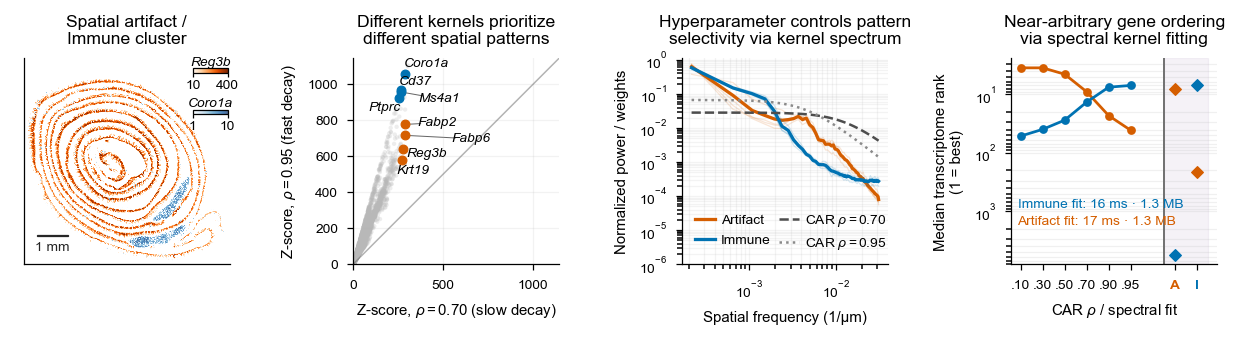

In [19]:
fig = manuscript_figure(48)
grid = fig.add_gridspec(1, 1, left=0.06, right=0.97, bottom=0.22, top=0.84)
draw_small_intestine_panel(
    fig,
    grid[0],
    pd.read_csv(SMALL_INTESTINE_SCORES_FILE),
    pd.read_csv(SMALL_INTESTINE_PATTERN_RANKS_FILE),
    small_intestine_maps,
    small_intestine_mask,
    small_intestine_genes,
)
preview_figure(fig, "Small-intestine kernel prioritization")

### Preview and save the combined main figure


Combined main Figure 2


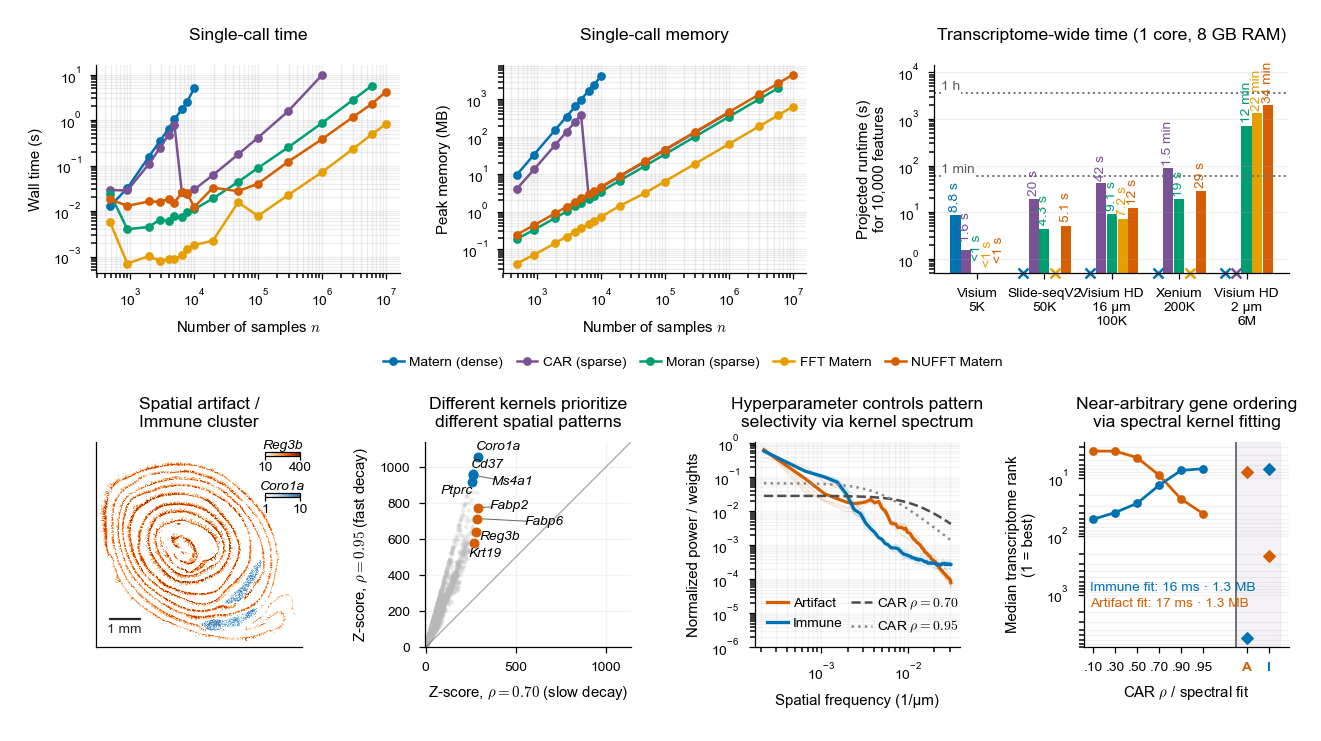

In [20]:
def build_runtime_small_intestine_figure() -> plt.Figure:
    benchmark = pd.read_csv(BENCHMARK_SCALING_FILE)
    projection = pd.read_csv(BENCHMARK_PROJECTION_FILE)
    scatter = pd.read_csv(SMALL_INTESTINE_SCORES_FILE)
    priority = pd.read_csv(SMALL_INTESTINE_PATTERN_RANKS_FILE)

    fig = manuscript_figure(105.0)
    outer = fig.add_gridspec(
        2,
        1,
        left=0.06,
        right=0.97,
        bottom=0.10,
        top=0.93,
        hspace=0.55,
        height_ratios=(0.75, 1.0),
    )
    draw_runtime_benchmark_panel(fig, outer[0], benchmark, projection)
    draw_small_intestine_panel(
        fig,
        outer[1],
        scatter,
        priority,
        small_intestine_maps,
        small_intestine_mask,
        small_intestine_genes,
    )
    return fig


with mpl.rc_context(COMPUTER_MODERN_MATHTEXT):
    preview_figure(build_runtime_small_intestine_figure(), "Combined main Figure 2")

In [21]:
with mpl.rc_context(COMPUTER_MODERN_MATHTEXT):
    save_figure(build_runtime_small_intestine_figure(), RUNTIME_MAIN_FIGURE_FILE)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


main_runtime.pdf


## Supplement: implementation validation figure


In [22]:
# Supplementary validation configuration
from .benchmark import load_validation_benchmark_results

METHODS = ("gaussian", "matern", "car", "moran")
METHOD_LABELS = {"gaussian": "Gaussian", "matern": "Matérn", "car": "CAR", "moran": "Moran"}
METHOD_COLORS = {
    "gaussian": PAPER_COLORS["gold"],
    "matern": PAPER_COLORS["cool"],
    "car": PAPER_COLORS["purple"],
    "moran": PAPER_COLORS["green"],
}
METHOD_MARKERS = {"gaussian": "o", "matern": "^", "car": "s", "moran": "D"}
SUPPLEMENTARY_IMPL_COLORS = {
    "Matrix": PAPER_COLORS["cool"],
    "FFT": PAPER_COLORS["gold"],
    "NUFFT": PAPER_COLORS["warm"],
}
NULL_LINESTYLES = {"welch": "-", "liu": ":", "clt": "--"}
NULL_MARKERS = {"welch": "o", "liu": "s", "clt": "D"}
SUPPLEMENTARY_STYLE = {
    "axes.titlesize": FONT_CONFIG["title"],
    "axes.labelsize": FONT_CONFIG["label"],
    "legend.fontsize": FONT_CONFIG["legend"],
    "legend.title_fontsize": FONT_CONFIG["legend"],
}

validation_results = load_validation_benchmark_results()

### Panel A: matrix and spectral implementation agreement


In [23]:
def _plot_signal_examples(fig: plt.Figure, ax_regular, ax_irregular) -> None:
    regular, coords, values = simulate_validation_signal_examples()
    image = ax_regular.imshow(regular, cmap="RdBu_r", origin="lower", vmin=-3, vmax=3)
    ax_regular.set_title("Matérn GP (regular grid)")
    fig.colorbar(image, ax=ax_regular, fraction=0.046, pad=0.03, ticks=(-2, 0, 2))

    domain = np.sqrt(coords.shape[0] / 2)
    scatter = ax_irregular.scatter(
        coords[:, 1],
        coords[:, 0],
        c=values,
        s=1.0,
        cmap="RdBu_r",
        vmin=-3,
        vmax=3,
        edgecolors="none",
        rasterized=True,
    )
    ax_irregular.set(xlim=(0, domain), ylim=(0, domain), aspect="equal")
    ax_irregular.set_title("Matérn GP (irregular grid)")
    fig.colorbar(scatter, ax=ax_irregular, fraction=0.046, pad=0.03, ticks=(-2, 0, 2))

    for ax in (ax_regular, ax_irregular):
        ax.set_axis_off()
        ax.set_box_aspect(1)
        ax.set_anchor("W")


def _relative_error(a: pd.Series, b: pd.Series) -> float:
    return float((np.abs(a - b) / np.maximum(np.abs(a), 1e-12)).mean())


def _plot_agreement_scatter(
    ax,
    data: pd.DataFrame,
    x: str,
    y: str,
    title: str,
    xlabel: str,
    ylabel: str,
    methods: tuple[str, ...] = METHODS,
    digits: str = ".1e",
) -> None:
    limits = [float(data[[x, y]].min().min()), float(data[[x, y]].max().max())]
    ax.plot(limits, limits, "--", color="0.5", lw=0.6)
    for method in methods:
        sub = data[data["method"].eq(method)]
        error = _relative_error(sub[x], sub[y])
        ax.scatter(
            sub[x],
            sub[y],
            s=3,
            alpha=0.72,
            marker=METHOD_MARKERS[method],
            color=METHOD_COLORS[method],
            edgecolors="none",
            rasterized=True,
            label=f"{METHOD_LABELS[method]} (rel err {error:{digits}})",
        )
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("symlog", linthresh=1)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(frameon=False, loc="upper left", handletextpad=0.3, labelspacing=0.2)


def draw_supplementary_agreement_panel(
    fig: plt.Figure, spec, results: dict[str, pd.DataFrame]
) -> None:
    """Draw signal examples and matrix-versus-spectral Q agreement."""
    grid = spec.subgridspec(2, 3, wspace=0.44, hspace=0.7, width_ratios=(0.95, 1.3, 1.35))
    ax_regular = fig.add_subplot(grid[0, 0])
    ax_torus = fig.add_subplot(grid[0, 1])
    ax_boundary = fig.add_subplot(grid[0, 2])
    ax_irregular = fig.add_subplot(grid[1, 0])
    ax_smooth = fig.add_subplot(grid[1, 1])
    graph = grid[1, 2].subgridspec(1, 2, wspace=0.58)
    ax_car = fig.add_subplot(graph[0, 0])
    ax_moran = fig.add_subplot(graph[0, 1])

    _plot_signal_examples(fig, ax_regular, ax_irregular)
    _plot_agreement_scatter(
        ax_torus,
        results["torus_agreement"],
        "Q_M",
        "Q_F",
        "FFT = Matrix on torus grid",
        r"$Q_{\rm Matrix}$ (torus)",
        r"$Q_{\rm FFT}$ (torus)",
    )
    _plot_agreement_scatter(
        ax_boundary,
        results["boundary_agreement"],
        "Q_M_open",
        "Q_F_torus",
        "Boundary mismatch changes Q statistics",
        r"$Q_{\rm Matrix}$ (open boundary)",
        r"$Q_{\rm FFT}$ (torus)",
        digits=".2f",
    )
    _plot_agreement_scatter(
        ax_smooth,
        results["smooth_agreement"],
        "Q_M",
        "Q_N",
        "NUFFT ≈ Matrix (distance-based)",
        r"$Q_{\rm Matrix}$",
        r"$Q_{\rm NUFFT}$",
        methods=("gaussian", "matern"),
        digits=".3f",
    )
    graph_data = results["graph_agreement"]
    for method, ax in (("car", ax_car), ("moran", ax_moran)):
        sub = graph_data[graph_data["method"].eq(method)]
        limits = [
            float(sub[["Q_M", "Q_N"]].min().min()),
            float(sub[["Q_M", "Q_N"]].max().max()),
        ]
        ax.plot(limits, limits, "--", color="0.5", lw=0.6)
        ax.scatter(
            sub["Q_M"],
            sub["Q_N"],
            s=3,
            alpha=0.7,
            color=METHOD_COLORS[method],
            edgecolors="none",
            rasterized=True,
        )
        ax.set(xlabel=r"$Q_{\rm Matrix}$", ylabel=r"$Q_{\rm NUFFT}$")
        ax.set_title(f"{METHOD_LABELS[method]} (different operator)")

Validation: implementation agreement


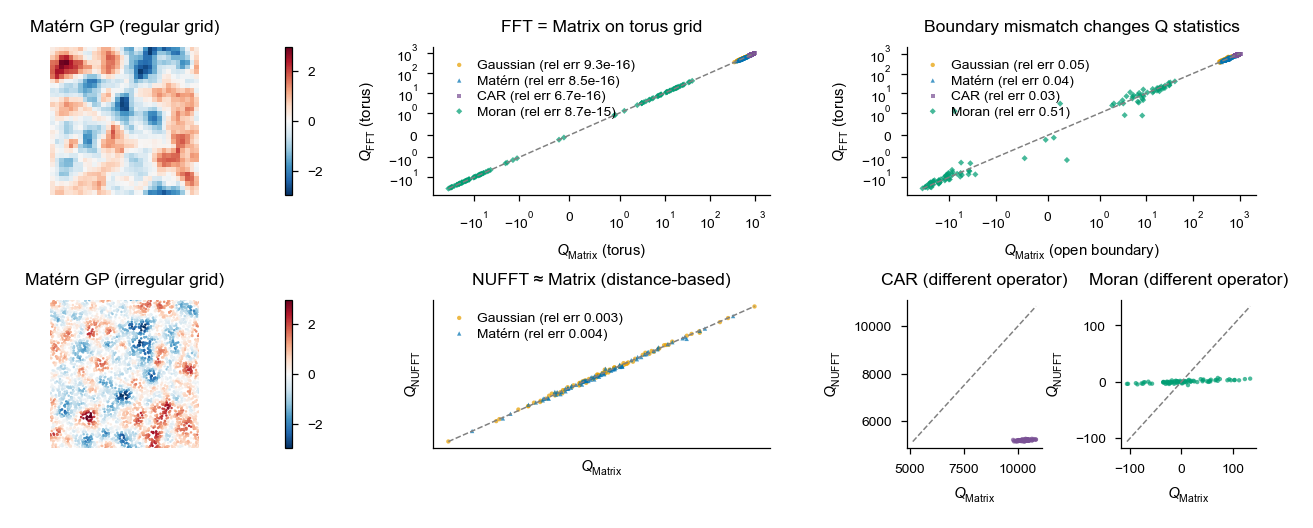

In [24]:
with mpl.rc_context(SUPPLEMENTARY_STYLE):
    fig = manuscript_figure(70)
    grid = fig.add_gridspec(1, 1, left=0.065, right=0.985, bottom=0.14, top=0.95)
    draw_supplementary_agreement_panel(fig, grid[0], validation_results)
    preview_figure(fig, "Validation: implementation agreement")

### Panel B: null calibration


In [25]:
def _plot_calibration_scatter(ax, pairs: pd.DataFrame) -> None:
    pairs = pairs.copy()
    pairs["x"] = -np.log10(np.maximum(pairs["p_welch"], 1e-12))
    pairs["y"] = -np.log10(np.maximum(pairs["p_liu"], 1e-12))
    plotted = pairs[pairs["method"].isin(("gaussian", "matern", "car"))]
    for (grid, method, impl), sub in plotted.groupby(["grid", "method", "impl"], sort=False):
        color = SUPPLEMENTARY_IMPL_COLORS[impl]
        ax.scatter(
            sub["x"],
            sub["y"],
            s=2,
            alpha=0.18,
            marker=METHOD_MARKERS[method],
            facecolors=color if grid == "regular" else "none",
            edgecolors=color,
            linewidths=0.25,
            rasterized=True,
        )
    limit = float(pairs[["x", "y"]].quantile(0.999).max())
    ax.plot((0, limit), (0, limit), "--", color="0.45", lw=0.6)
    ax.set(xlim=(-0.1, limit), ylim=(-0.1, limit))
    ax.set_xlabel(r"$-\log_{10}\,P_{\rm Welch}$")
    ax.set_ylabel(r"$-\log_{10}\,P_{\rm Liu}$")
    ax.set_title("Welch ≈ Liu across kernels")
    handles = [
        plt.Line2D([], [], marker="s", ls="", color=color, label=impl, ms=3)
        for impl, color in SUPPLEMENTARY_IMPL_COLORS.items()
    ]
    handles += [
        plt.Line2D(
            [],
            [],
            marker=METHOD_MARKERS[m],
            ls="",
            color="0.5",
            label=METHOD_LABELS[m],
            ms=3,
        )
        for m in ("gaussian", "matern", "car")
    ]
    handles += [
        plt.Line2D([], [], marker="o", ls="", color="0.5", label="Regular", ms=3),
        plt.Line2D(
            [],
            [],
            marker="o",
            ls="",
            markerfacecolor="none",
            color="0.5",
            label="Irregular",
            ms=3,
        ),
    ]
    ax.legend(handles=handles, frameon=False, loc="lower right", ncol=2, columnspacing=0.5)


def _plot_fpr(ax, data: pd.DataFrame, grid: str, second_impl: str) -> None:
    nulls = {"gaussian": "liu", "matern": "liu", "car": "liu", "moran": "clt"}
    width = 0.34
    for offset, impl in ((-width / 2, "Matrix"), (width / 2, second_impl)):
        values, errors = [], []
        for method in METHODS:
            row = data[
                data["grid"].eq(grid)
                & data["method"].eq(method)
                & data["impl"].eq(impl)
                & data["null"].eq(nulls[method])
            ].iloc[0]
            values.append(row["fpr"])
            errors.append(1.96 * row["se"])
        ax.bar(
            np.arange(4) + offset,
            values,
            width,
            yerr=errors,
            capsize=1.5,
            color=SUPPLEMENTARY_IMPL_COLORS[impl],
            label=impl,
            error_kw={"lw": 0.5},
        )
    ax.axhline(0.05, color="0.25", ls="--", lw=0.7, label=r"$\alpha=0.05$")
    ax.set_xticks(np.arange(4))
    ax.set_xticklabels([f"{METHOD_LABELS[m]}\n({nulls[m]})" for m in METHODS])
    ax.set_ylabel("False-positive rate")
    ax.set_ylim(0, 0.12)
    ax.set_title(f"FPR on {grid} grid (Matrix vs {second_impl})")
    ax.legend(frameon=False, loc="upper left")


def draw_supplementary_calibration_panel(
    fig: plt.Figure, spec, results: dict[str, pd.DataFrame]
) -> None:
    """Draw Welch/Liu agreement and regular/irregular false-positive rates."""
    grid = spec.subgridspec(1, 3, wspace=0.36, width_ratios=(0.8, 1.1, 1.1))
    _plot_calibration_scatter(fig.add_subplot(grid[0, 0]), results["welch_liu"])
    _plot_fpr(fig.add_subplot(grid[0, 1]), results["fpr"], "regular", "FFT")
    _plot_fpr(fig.add_subplot(grid[0, 2]), results["fpr"], "irregular", "NUFFT")

Validation: null calibration


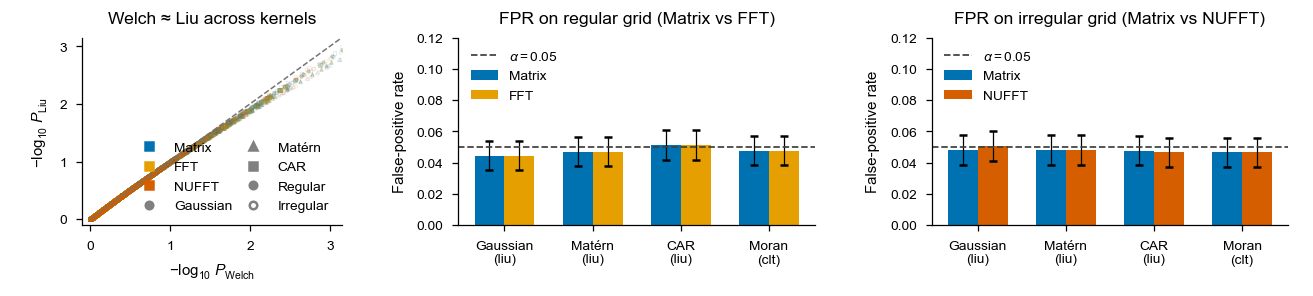

In [26]:
with mpl.rc_context(SUPPLEMENTARY_STYLE):
    fig = manuscript_figure(40)
    grid = fig.add_gridspec(1, 1, left=0.065, right=0.985, bottom=0.24, top=0.90)
    draw_supplementary_calibration_panel(fig, grid[0], validation_results)
    preview_figure(fig, "Validation: null calibration")

### Panel C: power across implementations and hyperparameters


In [27]:
def _jitter(values: pd.Series, impl: str, null: str) -> np.ndarray:
    offsets = {
        ("Matrix", "welch"): -2,
        ("Matrix", "liu"): -1,
        ("Matrix", "clt"): -1,
        ("FFT", "welch"): 0,
        ("FFT", "liu"): 1,
        ("FFT", "clt"): 1,
        ("NUFFT", "welch"): 2,
        ("NUFFT", "liu"): 2,
        ("NUFFT", "clt"): 2,
    }
    return values.to_numpy() + 0.004 * offsets[(impl, null)]


def draw_supplementary_power_panel(  # noqa: C901
    fig: plt.Figure, spec, results: dict[str, pd.DataFrame]
) -> None:
    """Draw regular, irregular, and hyperparameter-sweep power curves."""
    regular = results["power_regular"]
    irregular = results["power_irregular"]
    sweep = results["power_hyperparameter"]
    grid = spec.subgridspec(3, 4, wspace=0.18, hspace=0.08)
    axes = np.array([[fig.add_subplot(grid[row, col]) for col in range(4)] for row in range(3)])

    for row, data in enumerate((regular, irregular)):
        for col, method in enumerate(METHODS):
            ax = axes[row, col]
            sub = data[data["method"].eq(method)]
            for (impl, null), curve in sub.groupby(["impl", "null"]):
                curve = curve.sort_values("snr")
                color = SUPPLEMENTARY_IMPL_COLORS[impl]
                ax.plot(
                    _jitter(curve["snr"], impl, null),
                    curve["power"],
                    marker=NULL_MARKERS[null],
                    ls=NULL_LINESTYLES[null],
                    color=color,
                    lw=0.8,
                    ms=2.1,
                    mfc="none" if impl != "Matrix" else color,
                    mew=0.6,
                    label=f"{impl[0]}/{null.title()}",
                )
            ax.axhline(0.05, color="0.45", ls=":", lw=0.5)
            ax.legend(frameon=False, loc="lower right", handlelength=1.8, labelspacing=0.1)

    for col, method in enumerate(METHODS):
        ax = axes[2, col]
        sub = sweep[sweep["method"].eq(method)]
        values = sorted(sub["hp_value"].unique())
        colors = cm.viridis(np.linspace(0.15, 0.9, len(values)))
        hp_name = sub["hp_name"].iloc[0]
        for color, value in zip(colors, values, strict=True):
            curve = sub[sub["hp_value"].eq(value)].sort_values("snr")
            label = {"bandwidth": "bandwidth", "rho": "ρ", "k_neighbors": "k"}[hp_name]
            ax.plot(
                curve["snr"],
                curve["power"],
                "o-",
                color=color,
                lw=0.75,
                ms=1.8,
                label=f"{label}={value:g}",
            )
        ax.axhline(0.05, color="0.45", ls=":", lw=0.5)
        ax.legend(frameon=False, loc="lower right", labelspacing=0.1)

    for col, method in enumerate(METHODS):
        axes[0, col].set_title(METHOD_LABELS[method])
        axes[2, col].set_xlabel("Signal-to-noise ratio")
    row_labels = (
        "Power\n(regular grid)",
        "Power\n(irregular grid)",
        "Power\n(hyperparameter sweep)",
    )
    for row, label in enumerate(row_labels):
        axes[row, 0].set_ylabel(label)
    for ax in axes.ravel():
        ax.set_ylim(-0.02, 1.05)
        ax.grid(True, alpha=0.18)
    for ax in axes[:2].ravel():
        ax.tick_params(labelbottom=False)
    for ax in axes[:, 1:].ravel():
        ax.tick_params(labelleft=False)

Validation: power


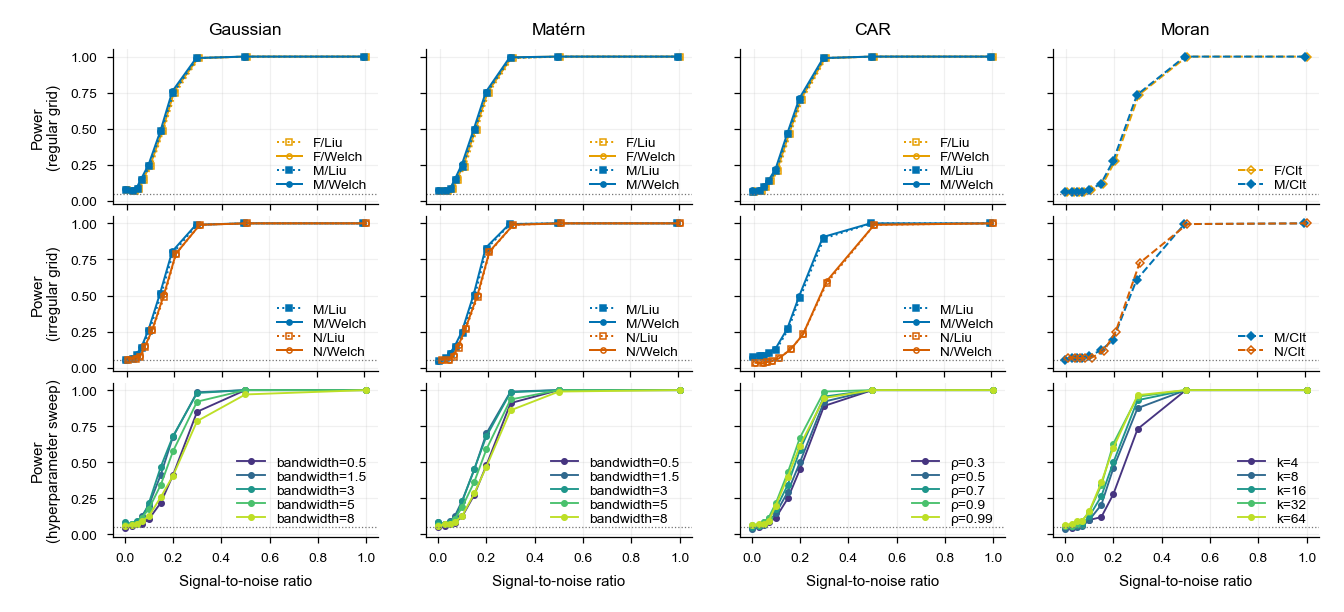

In [28]:
with mpl.rc_context(SUPPLEMENTARY_STYLE):
    fig = manuscript_figure(85)
    grid = fig.add_gridspec(1, 1, left=0.065, right=0.985, bottom=0.13, top=0.94)
    draw_supplementary_power_panel(fig, grid[0], validation_results)
    preview_figure(fig, "Validation: power")

### Preview and save the combined supplementary figure


Combined validation supplement


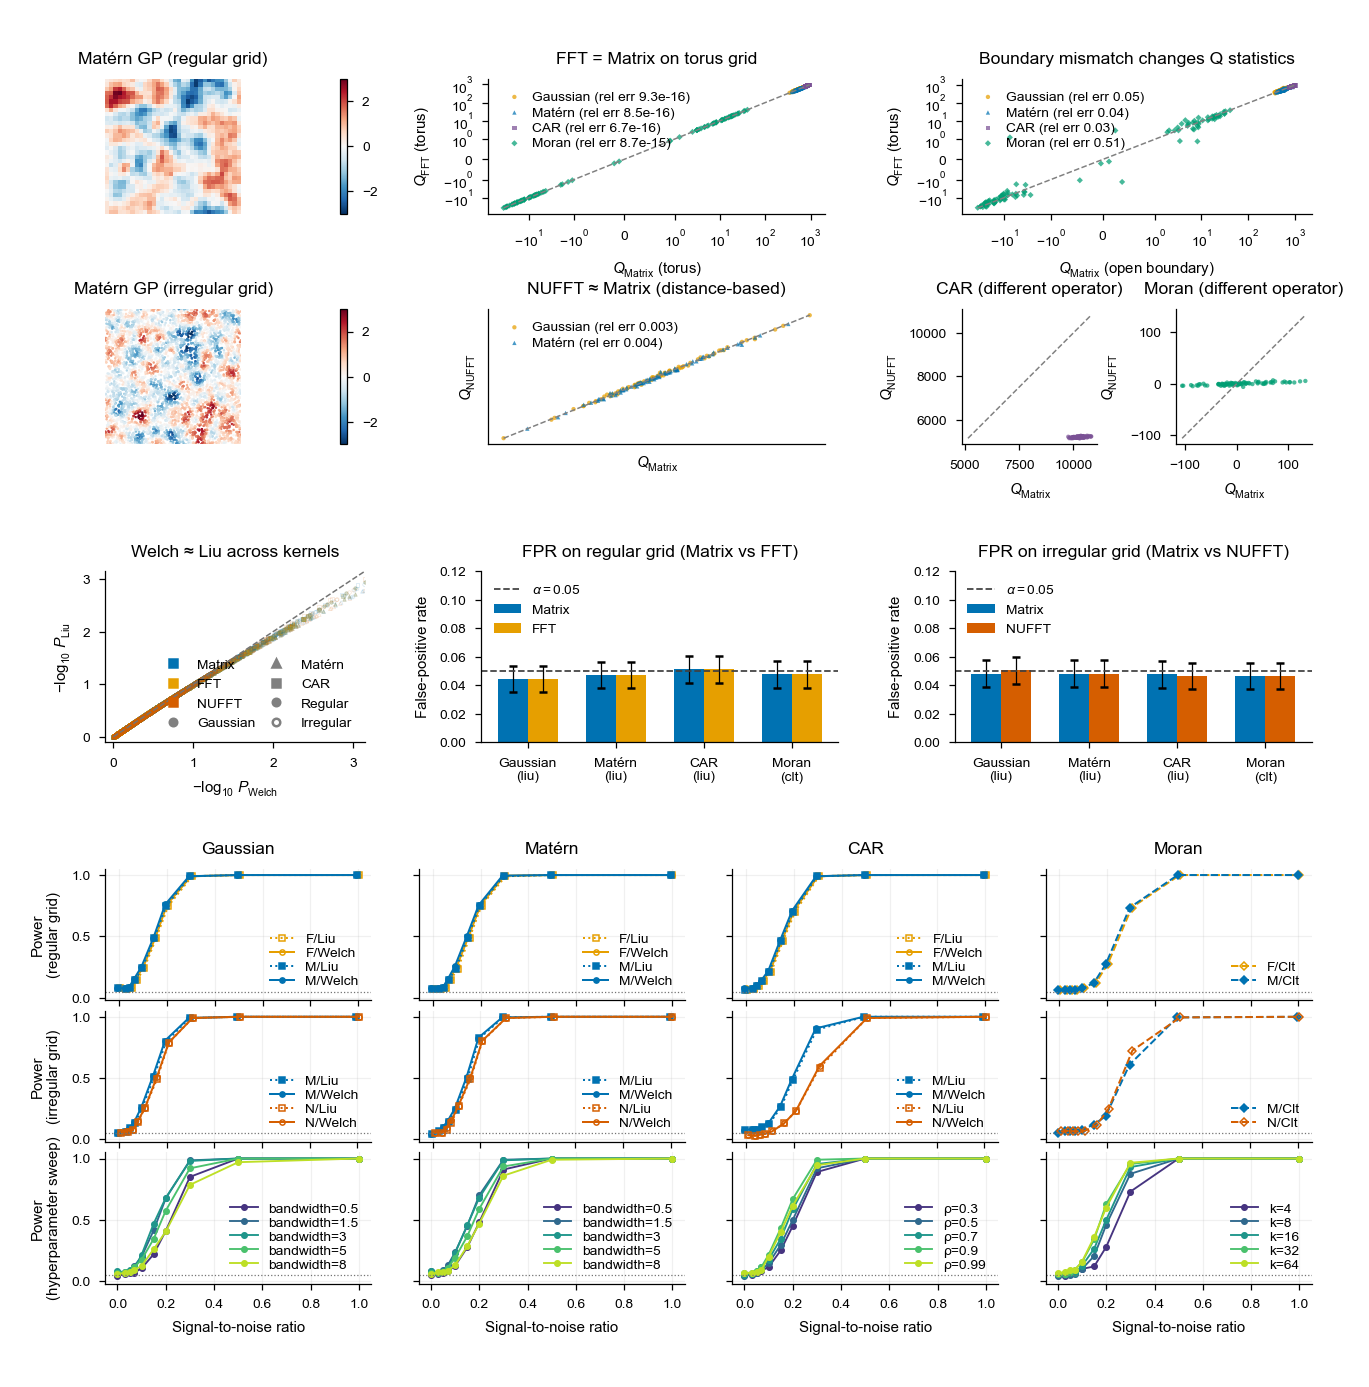

In [29]:
def build_validation_supplementary_figure() -> plt.Figure:
    with mpl.rc_context(SUPPLEMENTARY_STYLE):
        fig = manuscript_figure(190)
        outer = fig.add_gridspec(
            3,
            1,
            left=0.065,
            right=0.985,
            bottom=0.055,
            top=0.95,
            hspace=0.4,
            height_ratios=(0.75, 0.35, 0.85),
        )
        draw_supplementary_agreement_panel(fig, outer[0], validation_results)
        draw_supplementary_calibration_panel(fig, outer[1], validation_results)
        draw_supplementary_power_panel(fig, outer[2], validation_results)
    return fig


preview_figure(build_validation_supplementary_figure(), "Combined validation supplement")

In [30]:
save_figure(
    build_validation_supplementary_figure(),
    VALIDATION_SUPPLEMENTARY_FIGURE_FILE,
)

supp_validation.pdf


## Main Figure 3: single-cell lineage tracing

All tests and spectral decompositions come from workflow caches. The notebook derives
only lightweight tabular summaries and tree coordinates needed for plotting.


In [31]:
import seaborn as sns
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import dendrogram, fcluster, leaves_list, linkage
from scipy.optimize import linear_sum_assignment
from scipy.sparse.csgraph import minimum_spanning_tree

from .config import (
    LINEAGE_BIVARIATE_DIAGNOSTICS_FILE,
    LINEAGE_BIVARIATE_SUMMARY_FILE,
    LINEAGE_CLUSTER_SCORES_FILE,
    LINEAGE_GENE_DIAGNOSTICS_FILE,
    LINEAGE_GENE_SCORES_FILE,
    LINEAGE_MAIN_FIGURE_FILE,
    LINEAGE_SUPPLEMENTARY_FIGURE_FILE,
    LINEAGE_TARGET_METADATA_FILE,
    LINEAGE_TREE_DIR,
)
from .lineage import GENE_PANEL
from .utils import parse_newick

cache_files = (
    LINEAGE_CLUSTER_SCORES_FILE,
    LINEAGE_GENE_SCORES_FILE,
    LINEAGE_BIVARIATE_SUMMARY_FILE,
    LINEAGE_GENE_DIAGNOSTICS_FILE,
    LINEAGE_BIVARIATE_DIAGNOSTICS_FILE,
    LINEAGE_TARGET_METADATA_FILE,
)
require_files(
    cache_files,
    label="lineage caches; run lineage.cache_lineage_results first",
)

cluster_scores = pd.read_csv(LINEAGE_CLUSTER_SCORES_FILE)

# Load per-gene scores and compute summary statistics, recovery curves, and concordance by gene groups.
gene_scores = pd.read_csv(LINEAGE_GENE_SCORES_FILE)
gene_summary_records = []
gene_recovery_records = []
rank_records = []
rank_labels = ("Broad", "Mid-low", "Mid-high", "Restricted")
for tumor, table in gene_scores.groupby("Tumor", sort=False):
    significant = table["Sig_moran"].astype(bool)
    gene_summary_records.append(
        {
            "Tumor": tumor,
            "Rho_Sig_Moran": table.loc[significant, "I_moran"].corr(
                table.loc[significant, "Z_score_car"], method="spearman"
            ),
            "Rho_NonSig_Moran": table.loc[~significant, "I_moran"].corr(
                table.loc[~significant, "Z_score_car"], method="spearman"
            ),
        }
    )
    hits = table["Sig_car"].astype(bool).to_numpy()
    if hits.sum() >= 10:
        ordered = table.assign(_hit=hits).sort_values("I_moran", ascending=False)
        keep = np.unique(np.linspace(0, len(ordered) - 1, min(400, len(ordered))).astype(int))
        gene_recovery_records.append(
            pd.DataFrame(
                {
                    "Tumor": tumor,
                    "Rank_fraction": np.linspace(0, 1, len(ordered))[keep],
                    "Recovered_fraction": (ordered["_hit"].cumsum().to_numpy() / hits.sum())[keep],
                }
            )
        )
    # Group genes by sparsity rank and compute median sparsity and rank correlation within each bin.
    support_bin = pd.qcut(
        table["Sparsity"].rank(method="first"), len(rank_labels), labels=rank_labels
    )
    for order, label in enumerate(rank_labels):
        group = table.loc[support_bin.eq(label)]
        rank_records.append(
            {
                "Tumor": tumor,
                "Support_bin": label,
                "Bin_order": order,
                "N_genes": len(group),
                "Median_sparsity": group["Sparsity"].median(),
                "Rank_correlation": group["Z_score_moran"].corr(
                    group["Z_score_car"], method="spearman"
                ),
            }
        )
gene_summary = pd.DataFrame.from_records(gene_summary_records)
gene_recovery = pd.concat(gene_recovery_records, ignore_index=True)
gene_rank_concordance = pd.DataFrame.from_records(rank_records)

# Load spectral profiles and diagnostics of selected genes
gene_spectral = np.load(LINEAGE_GENE_DIAGNOSTICS_FILE)
gene_cancellation = pd.DataFrame(
    {
        "Feature": gene_spectral["features"].astype(str),
        "Sparsity": gene_spectral["sparsity"],
        "Positive_contribution": gene_spectral["positive_contribution"],
        "Negative_contribution": gene_spectral["negative_contribution"],
        "Cancellation_fraction": gene_spectral["cancellation_fraction"],
        "Call": gene_spectral["calls"].astype(str),
        "Small_state_marker": gene_spectral["small_state_markers"].astype(bool),
    }
)
MISSED_GENE = str(gene_spectral["example_gene"])

# Load bivariate scores and diagnostics of selected gene pairs
bivariate_summary = pd.read_csv(LINEAGE_BIVARIATE_SUMMARY_FILE)
target_metadata = pd.read_csv(LINEAGE_TARGET_METADATA_FILE).set_index("Cell")
bivariate = np.load(LINEAGE_BIVARIATE_DIAGNOSTICS_FILE)
spectral = {
    key: bivariate[key]
    for key in (
        "cells",
        "pair_genes",
        "pair_expression",
        "eigenvalues",
        "coefficients",
        "contributions",
        "selected_modes",
        "selected_vectors",
    )
}
bivariate_genes = bivariate["genes"].astype(str)
bivariate_upper = np.triu_indices(len(bivariate_genes))
bivariate_pairs = pd.DataFrame(
    {
        "Gene_1": bivariate_genes[bivariate_upper[0]],
        "Gene_2": bivariate_genes[bivariate_upper[1]],
        "Z_Moran": bivariate["z_moran"],
        "Z_CAR": bivariate["z_car"],
        "Group": np.asarray(("Consistent", "Moran dominant", "CAR dominant"))[bivariate["group"]],
    }
)
bivariate_moran = np.zeros((len(bivariate_genes), len(bivariate_genes)), dtype=np.float32)
bivariate_car = np.zeros_like(bivariate_moran)
for matrix, values in (
    (bivariate_moran, bivariate["z_moran"]),
    (bivariate_car, bivariate["z_car"]),
):
    matrix[bivariate_upper] = values
    matrix[(bivariate_upper[1], bivariate_upper[0])] = values
bivariate_regression = bivariate["regression"]


# Resolve per-tumor lineage trees and compute radial layouts for visualization.
def _tree_layout_from_newick(path):
    root, children, _, leaves = parse_newick(path)
    angles = dict(
        zip(
            leaves, np.linspace(-np.pi / 2, 3 * np.pi / 2, len(leaves), endpoint=False), strict=True
        )
    )
    depths = {root: 0}
    stack = [root]
    while stack:
        node = stack.pop()
        for child in children.get(node, ()):
            depths[child] = depths[node] + 1
            stack.append(child)

    def assign_angle(node):
        if node not in angles:
            angles[node] = np.mean([assign_angle(child) for child in children[node]])
        return angles[node]

    assign_angle(root)
    maximum_depth = max(depths.values())
    radii = {node: (1.0 if node in leaves else depths[node] / maximum_depth) for node in depths}
    segments = []
    for node, node_children in children.items():
        radius = radii[node]
        child_angles = np.asarray([angles[child] for child in node_children])
        if len(child_angles) > 1 and radius > 0:
            arc_angles = np.linspace(child_angles.min(), child_angles.max(), 12)
            arc = np.column_stack((radius * np.cos(arc_angles), radius * np.sin(arc_angles)))
            segments.extend(np.column_stack((arc[:-1], arc[1:])))
        for child in node_children:
            angle = angles[child]
            segments.append(
                np.asarray(
                    (
                        radius * np.cos(angle),
                        radius * np.sin(angle),
                        radii[child] * np.cos(angle),
                        radii[child] * np.sin(angle),
                    )
                )
            )
    return np.asarray(segments), np.asarray([angles[leaf] for leaf in leaves]), np.asarray(leaves)


tree_layouts = {}
for tumor in ("3430_NT_T2", "3730_NT_T2"):
    edges, angles, leaves = _tree_layout_from_newick(LINEAGE_TREE_DIR / f"{tumor}.newick")
    tree_layouts[f"{tumor}_edges"] = edges
    tree_layouts[f"{tumor}_leaf_angles"] = angles
    tree_layouts[f"{tumor}_leaves"] = leaves

PAIR_GENES = tuple(spectral["pair_genes"].tolist())
CONSISTENT_COLOR = PAPER_COLORS["light"]
MORAN_COLOR, CAR_COLOR = PAPER_COLORS["green"], PAPER_COLORS["purple"]
BOTH_COLOR, CAR_ONLY_COLOR = PAPER_COLORS["warm"], PAPER_COLORS["cool"]
POSITIVE_MODE_COLOR, NEGATIVE_MODE_COLOR = PAPER_COLORS["warm"], PAPER_COLORS["cool"]
clusters = sorted(cluster_scores["Cluster"].dropna().unique())
if len(clusters) > len(PAPER_CATEGORICAL):
    raise ValueError("Lineage cluster count exceeds the shared categorical palette")
CLUSTER_COLORS = dict(zip(clusters, PAPER_CATEGORICAL[: len(clusters)], strict=True))
dominant_cluster = (
    target_metadata.loc[target_metadata["Tumor"].eq("3430_NT_T2"), "Cluster-Name"]
    .value_counts()
    .idxmax()
)
CLUSTER_COLORS[dominant_cluster] = PAPER_COLORS["charcoal"]
print("lineage caches loaded:", len(bivariate_pairs), "target gene pairs")

lineage caches loaded: 205761 target gene pairs


### Shared lineage plotting helpers


In [32]:
def _despine(ax, *, bottom=False):
    sns.despine(ax=ax, bottom=bottom)
    ax.grid(axis="y", color="0.9", lw=0.5, zorder=0)


def _draw_radial_tree(  # noqa: C901
    ax, tumor, tracks, title, *, show_track_note=True, terminal_branch_colors=None
):
    edges = tree_layouts[f"{tumor}_edges"]
    angles = tree_layouts[f"{tumor}_leaf_angles"]
    leaves = tree_layouts[f"{tumor}_leaves"].astype(str)
    segments = edges.reshape(-1, 2, 2)
    ax.add_collection(LineCollection(segments, color="0.62", lw=0.35, alpha=0.75))
    if terminal_branch_colors is not None:
        aligned_colors = pd.Series(terminal_branch_colors).reindex(leaves)
        if aligned_colors.isna().any():
            raise ValueError("Terminal-branch colors do not cover every tree leaf")
        radii = np.linalg.norm(segments, axis=2)
        terminal = np.isclose(radii.max(axis=1), 1.0)
        terminal_segments = segments[terminal]
        terminal_radii = radii[terminal]
        outer_points = terminal_segments[
            np.arange(len(terminal_segments)), terminal_radii.argmax(axis=1)
        ]
        terminal_angles = np.arctan2(outer_points[:, 1], outer_points[:, 0])
        distances = np.abs(np.angle(np.exp(1j * (terminal_angles[:, None] - angles[None, :]))))
        leaf_indices = distances.argmin(axis=1)
        ax.add_collection(
            LineCollection(
                terminal_segments,
                colors=aligned_colors.iloc[leaf_indices].tolist(),
                linewidths=0.75,
                zorder=2,
            )
        )
    track_spacing = 0.05
    axis_size_points = (
        min(
            ax.get_position().width * ax.figure.get_figwidth(),
            ax.get_position().height * ax.figure.get_figheight(),
        )
        * 72
    )
    ring_width = 0.72 * track_spacing * axis_size_points / 2.44
    half_bin = 0.505 * 2 * np.pi / len(leaves)
    for index, (label, values, color_spec) in enumerate(tracks):
        radius = 1.0 + track_spacing * index
        aligned = pd.Series(values).reindex(leaves)
        if aligned.isna().any():
            missing_leaves = aligned.index[aligned.isna()].tolist()
            raise ValueError(f"Track {label!r} lacks {len(missing_leaves)} tree leaves")
        if isinstance(color_spec, dict):
            missing_categories = set(aligned).difference(color_spec)
            if missing_categories:
                raise ValueError(f"Track {label!r} lacks colors for {sorted(missing_categories)}")
            colors = [color_spec[value] for value in aligned]
        else:
            numeric = aligned.to_numpy(float)
            if label.startswith("mode "):
                magnitudes = np.abs(numeric)
                nonzero = magnitudes[magnitudes > 0]
                limit = np.quantile(nonzero, 0.95) if len(nonzero) else 0
                if limit <= 0:
                    raise ValueError(f"Track {label!r} has no spectral variation")
                scaled = 0.5 + 0.5 * np.clip(numeric / limit, -1, 1)
            else:
                lo = np.min(numeric)
                above_minimum = numeric[numeric > lo]
                hi = np.quantile(above_minimum, 0.95) if len(above_minimum) else lo
                if hi <= lo:
                    raise ValueError(f"Track {label!r} has no expression variation")
                scaled = np.clip((numeric - lo) / (hi - lo), 0, 1)
            cmap = mpl.colormaps[color_spec] if isinstance(color_spec, str) else color_spec
            colors = cmap(scaled)
        arcs = [
            np.column_stack((radius * np.cos(theta), radius * np.sin(theta)))
            for theta in (np.linspace(angle - half_bin, angle + half_bin, 3) for angle in angles)
        ]
        ax.add_collection(
            LineCollection(
                arcs, colors=colors, linewidths=ring_width, capstyle="butt", rasterized=True
            )
        )
    ax.set(xlim=(-1.22, 1.22), ylim=(-1.22, 1.22), aspect="equal")
    ax.axis("off")
    ax.set_title(title, pad=1, y=1.05)
    if len(tracks) > 1 and show_track_note:
        ax.text(
            0.5,
            -0.01,
            "Tracks, inner to outer: " + ", ".join(label for label, _, _ in tracks),
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=5.5,
        )

### Panel A: graph-based test illustration


In [33]:
def _draw_synthetic_phylogeny(fig, spec):
    rng = np.random.RandomState(42)
    n_clones, cells_per_clone = 5, 20
    clone_labels = np.repeat(np.arange(n_clones), cells_per_clone)
    clone_centers = rng.randn(n_clones, 10) * 2.5
    genotypes = clone_centers[clone_labels] + rng.normal(0, 0.2, (clone_labels.size, 10))
    hierarchy = linkage(genotypes, method="ward")
    leaf_order = dendrogram(hierarchy, no_plot=True)["leaves"]
    ordered_clones = clone_labels[leaf_order]

    clone_values = np.linspace(-1.5, 1.5, n_clones)
    rng.shuffle(clone_values)
    heritable = clone_values[ordered_clones] + rng.normal(0, 0.1, clone_labels.size)
    plastic = heritable + rng.normal(0, 1.0, clone_labels.size)
    coexpressed = heritable + rng.normal(0, 0.3, clone_labels.size)
    adjacency = np.diag(np.ones(clone_labels.size - 1), 1) + np.diag(
        np.ones(clone_labels.size - 1), -1
    )
    weights = adjacency / adjacency.sum(axis=1, keepdims=True)
    centering = (
        np.eye(clone_labels.size)
        - np.ones((clone_labels.size, clone_labels.size)) / clone_labels.size
    )
    _, eigenvectors = np.linalg.eigh(centering @ weights @ centering)
    anti = -heritable + 2.5 * eigenvectors[:, 0]
    features = np.column_stack((heritable, plastic, coexpressed, anti))
    features = (features - features.mean(axis=0)) / features.std(axis=0)

    grid = spec.subgridspec(1, 2, width_ratios=(1.0, 0.30), wspace=0.025)
    ax = fig.add_subplot(grid[0])
    dendrogram(
        hierarchy,
        orientation="left",
        no_labels=True,
        color_threshold=0,
        above_threshold_color="0.56",
        link_color_func=lambda _: "0.56",
        ax=ax,
    )
    for collection in ax.collections:
        collection.set_linewidth(0.45)
    ax.axis("off")
    ax.set_title("Phylogenetic graph by barcodes", pad=2, y=1.02, ha="left", x=0.0)

    ax = fig.add_subplot(grid[1])
    feature_cmap = paper_diverging_cmap("synthetic_lineage")
    ax.imshow(
        features[leaf_order[::-1]],
        aspect="auto",
        cmap=feature_cmap,
        vmin=-2,
        vmax=2,
        interpolation="nearest",
        rasterized=True,
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def _draw_relation_concept(fig, spec):
    grid = spec.subgridspec(1, 4, width_ratios=(1.0, 1.0, 1.12, 1.38), wspace=0.30)
    cmap = paper_diverging_cmap("lineage_features")
    rng = np.random.default_rng(24)

    def draw_knn_graph(ax, coordinates, feature, title, n_neighbors):
        distances = np.linalg.norm(coordinates[:, None, :] - coordinates[None, :, :], axis=2)
        neighbors = np.argsort(distances, axis=1)[:, 1 : n_neighbors + 1]
        edges = {
            tuple(sorted((index, int(neighbor))))
            for index, row in enumerate(neighbors)
            for neighbor in row
        }
        spanning_tree = minimum_spanning_tree(distances).tocoo()
        edges.update(
            tuple(sorted((int(left), int(right))))
            for left, right in zip(spanning_tree.row, spanning_tree.col, strict=True)
        )
        edges = sorted(edges)
        segments = np.asarray([[coordinates[left], coordinates[right]] for left, right in edges])
        ax.add_collection(
            LineCollection(segments, colors="0.76", linewidths=0.5, alpha=0.68, zorder=0)
        )
        ax.scatter(
            coordinates[:, 0],
            coordinates[:, 1],
            c=feature,
            cmap=cmap,
            vmin=-2.5,
            vmax=2.5,
            s=9,
            edgecolor="white",
            linewidth=0.5,
            zorder=2,
            rasterized=True,
        )
        ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal")
        ax.set_anchor("N")
        ax.axis("off")
        ax.set_title(title, pad=2, y=1.02)

    # Spatial pattern detection
    spatial_x, spatial_y = np.meshgrid(np.linspace(0.06, 0.94, 9), np.linspace(0.06, 0.94, 8))
    spatial_coordinates = np.column_stack((spatial_x.ravel(), spatial_y.ravel())) + rng.normal(
        scale=0.018, size=(72, 2)
    )
    spatial_feature = 1.35 * np.sin(2 * np.pi * spatial_coordinates[:, 0]) + 1.10 * np.cos(
        2 * np.pi * spatial_coordinates[:, 1]
    )
    draw_knn_graph(
        fig.add_subplot(grid[0]), spatial_coordinates, spatial_feature, "Physical-neighbor graph", 6
    )

    # Single-cell graph pattern detection
    groups = np.repeat(np.arange(3), 16)
    centers = np.asarray(((0.25, 0.30), (0.72, 0.34), (0.50, 0.76)))
    expression_coordinates = centers[groups] + rng.normal(scale=0.085, size=(groups.size, 2))
    expression_coordinates = (expression_coordinates - expression_coordinates.min(axis=0)) / np.ptp(
        expression_coordinates, axis=0
    )
    expression_feature = np.asarray((-1.7, 0.2, 1.7))[groups] + rng.normal(
        scale=0.28, size=groups.size
    )
    draw_knn_graph(
        fig.add_subplot(grid[1]),
        expression_coordinates,
        expression_feature,
        "Transcriptomic k-NN graph",
        4,
    )

    # Phylogenetic graph pattern detection
    _draw_synthetic_phylogeny(fig, grid[2])

    cards = grid[3].subgridspec(2, 1, hspace=0.13)
    card_data = (
        (
            "Intrinsic Q (univariate)",
            r"$Q=z^\mathsf{T}Kz$",
            "Is one feature variable along the graph?",
            "#e8f1fa",
            PAPER_COLORS["cool"],
        ),
        (
            "Relational R (bivariate)",
            r"$R=z_x^\mathsf{T}Kz_y$",
            "Are two features colocalized on the graph?",
            "#f6ebf5",
            PAPER_COLORS["purple"],
        ),
    )
    for row, (title, statistic, question, face, edge) in enumerate(card_data):
        ax = fig.add_subplot(cards[row])
        if row == 0:
            ax.set_title("Shared test statistics", pad=2, y=1.02)
        ax.axis("off")
        ax.add_patch(
            mpl.patches.FancyBboxPatch(
                (0.03, 0.08),
                0.94,
                0.84,
                boxstyle="round,pad=0.025",
                facecolor=face,
                edgecolor=edge,
                lw=0.7,
            )
        )
        ax.text(0.5, 0.72, title, ha="center", va="center", fontsize=6.0)
        ax.text(0.5, 0.47, statistic, ha="center", va="center", fontsize=7.0)
        ax.text(0.5, 0.22, question, ha="center", va="center", fontsize=5.5)

Lineage: graph analysis concept


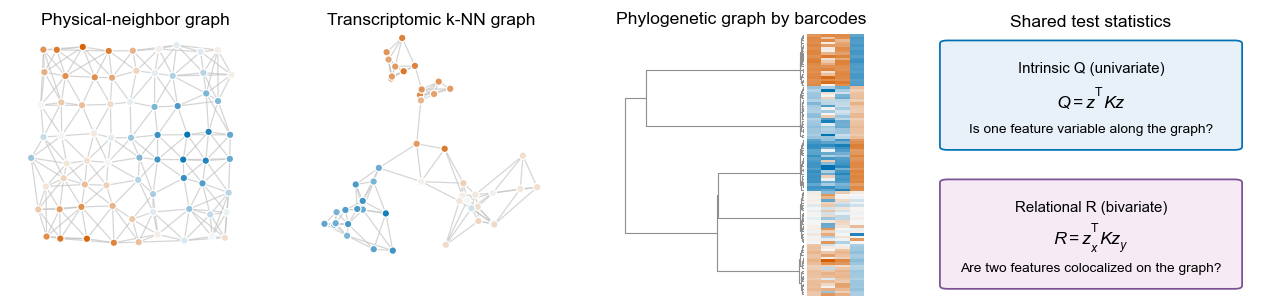

In [34]:
fig = manuscript_figure(48)
grid = fig.add_gridspec(1, 1, left=0.055, right=0.985, bottom=0.15, top=0.92)
_draw_relation_concept(fig, grid[0])
preview_figure(fig, "Lineage: graph analysis concept")

### Panels B-D: Moran missed phylogenetic patterns


In [35]:
def _draw_3430NTT2_scatter(ax):
    """Scatter plot of Moran vs CAR scores for 3430_NT_T2."""
    target = gene_scores[gene_scores["Tumor"].eq("3430_NT_T2")].copy()
    # Group genes by significance calls for coloring and labeling
    both = target["Sig_car"].astype(bool) & target["Sig_moran"].astype(bool)
    car_only = target["Sig_car"].astype(bool) & ~target["Sig_moran"].astype(bool)
    background = ~target["Sig_car"].astype(bool)
    ax.scatter(
        target.loc[background, "Z_score_moran"],
        target.loc[background, "Z_score_car"],
        color=CONSISTENT_COLOR,
        s=2,
        alpha=0.13,
        edgecolor="none",
        rasterized=True,
    )
    ax.scatter(
        target.loc[both, "Z_score_moran"],
        target.loc[both, "Z_score_car"],
        color=BOTH_COLOR,
        label="Both",
        s=5,
        alpha=0.55,
        edgecolor="none",
        rasterized=True,
    )
    ax.scatter(
        target.loc[car_only, "Z_score_moran"],
        target.loc[car_only, "Z_score_car"],
        color=CAR_ONLY_COLOR,
        label="CAR only",
        s=5,
        alpha=0.55,
        rasterized=True,
    )

    # Label selected gene examples
    annotated = target[target["Feature"].isin(GENE_PANEL)]
    ax.scatter(
        annotated["Z_score_moran"],
        annotated["Z_score_car"],
        color=CAR_ONLY_COLOR,
        s=15,
        marker="*",
        zorder=4,
    )
    box_style = {
        "boxstyle": "round,pad=0.1",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.5,
    }
    labels = [
        ax.text(
            row.Z_score_moran,
            row.Z_score_car,
            row.Feature,
            fontsize=6.0,
            fontstyle="italic",
            bbox=box_style,
        )
        for row in annotated.itertuples()
    ]
    adjust_text(
        labels,
        x=annotated["Z_score_moran"],
        y=annotated["Z_score_car"],
        ax=ax,
        arrowprops={"arrowstyle": "-", "color": "0.45", "lw": 0.5},
    )
    ax.axvline(
        target.loc[target["Sig_moran"], "Z_score_moran"].min(), color="0.45", lw=0.5, ls="--"
    )
    ax.axhline(target.loc[target["Sig_car"], "Z_score_car"].min(), color="0.45", lw=0.5, ls="--")
    ax.set(xlabel="Standardized Moran's I", ylabel="Standardized CAR-Q")
    _despine(ax)

    # Add a legend for the significance groups
    lg = ax.legend(
        frameon=False,
        loc="upper left",
        handletextpad=0.3,
        title="FDR calls",
        title_fontsize=5.5,
    )
    for lh in lg.legend_handles:
        lh.set_alpha(1.0)
        lh.set_sizes([15])


def draw_gene_story(fig, spec):
    grid = spec.subgridspec(1, 3, width_ratios=(1.0, 0.8, 1.4), wspace=0.4)

    # Moran vs CAR scatter for 3430_NT_T2
    ax = fig.add_subplot(grid[0])
    _draw_3430NTT2_scatter(ax)

    meta = target_metadata[target_metadata["Tumor"].eq("3430_NT_T2")]
    state_counts = meta["Cluster-Name"].value_counts()
    state_order = state_counts.index

    # Phylogenetic tree with cell states and gene-expression tracks
    ax = fig.add_subplot(grid[1])
    gene_tracks = [
        (gene, meta[gene], cmap)
        for gene, cmap in zip(
            GENE_PANEL,
            ("Reds", "Blues", "Greens", "Purples"),
            strict=True,
        )
    ]
    tracks = [
        ("cell state", meta["Cluster-Name"], CLUSTER_COLORS),
        *gene_tracks,
    ]
    highlighted_states = {"AT2-like", "Gastric-like", "High plasticity"}
    minor_branch_colors = meta["Cluster-Name"].map(
        lambda state: (
            mcolors.to_rgba(CLUSTER_COLORS[state], 0.9)
            if state in highlighted_states
            else mcolors.to_rgba("0.65", 0)
        )
    )
    _draw_radial_tree(
        ax,
        "3430_NT_T2",
        tracks,
        "",
        show_track_note=False,
        terminal_branch_colors=minor_branch_colors,
    )
    for index in range(1, len(tracks)):
        ax.add_patch(
            mpl.patches.Circle(
                (0, 0),
                1.0 + 0.05 * (index - 0.5),
                fill=False,
                edgecolor="0.72",
                linewidth=0.3,
                zorder=4,
            )
        )
    ax.text(
        0.5,
        -0.04,
        "Inner ring: cell state",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=5.5,
    )
    add_gene_label(
        ax,
        "Gene rings, inner to outer: ",
        GENE_PANEL,
        xy=(0.5, -0.085),
        fontsize=5.5,
        loc="upper center",
    )
    ax.set_anchor("N")

    # Selected gene expression across cell states
    gene_grid = grid[2].subgridspec(2, 2, hspace=0.44, wspace=0.34)
    for index, gene in enumerate(GENE_PANEL):
        ax = fig.add_subplot(gene_grid[index])
        sns.violinplot(
            data=meta,
            x="Cluster-Name",
            y=gene,
            order=state_order,
            hue="Cluster-Name",
            palette=CLUSTER_COLORS,
            legend=False,
            inner=None,
            cut=0,
            linewidth=0.5,
            ax=ax,
        )
        ax.set(xlabel="", ylabel="Expression")
        ax.set_title(gene, fontstyle="italic", pad=2)
        ax.tick_params(axis="x", labelbottom=False, length=0)
        _despine(ax)

    # Expand the counted cell-state legend beneath the tree and violins.
    state_handles = [
        Patch(
            color=CLUSTER_COLORS[state],
            label=f"{state} (n={state_counts[state]:,})",
        )
        for state in state_order
    ]
    legend_ax = fig.add_subplot(grid[:, 1:])
    legend_ax.axis("off")
    legend_ax.legend(
        handles=state_handles,
        loc="upper left",
        bbox_to_anchor=(0, -0.06, 1, 0),
        mode="expand",
        ncol=4,
        frameon=False,
        fontsize=5.5,
        handlelength=0.8,
        columnspacing=0.7,
        labelspacing=0.25,
        borderaxespad=0,
    )

Lineage: missed heritable genes


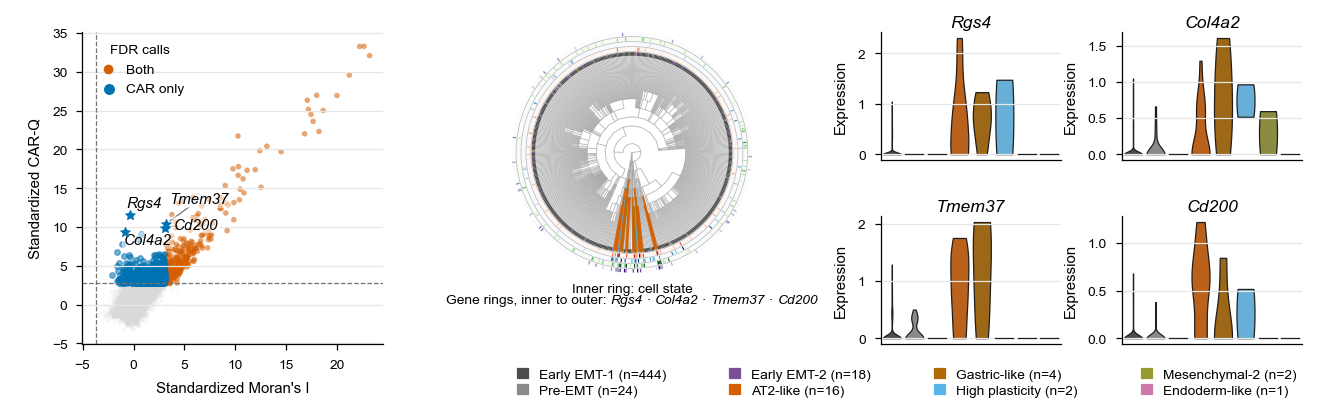

In [36]:
fig = manuscript_figure(50)
outer = fig.add_gridspec(
    1,
    1,
    left=0.055,
    right=0.985,
    bottom=0.08,
    top=0.96,
)
draw_gene_story(fig, outer[0])
preview_figure(fig, "Lineage: missed heritable genes")

### Panels E-G: Moran cancellation

In [37]:
def _draw_rank_concordance(ax):
    """Plot rank correlation between Moran and CAR scores for genes grouped by sparsity bins."""
    summary = gene_rank_concordance.sort_values(["Tumor", "Bin_order"])
    # Per-(tumor, gene-group) rank correlation curves
    for _, table in summary.groupby("Tumor", sort=False):
        ax.plot(
            table["Bin_order"],
            table["Rank_correlation"],
            color="0.72",
            lw=0.5,
            marker="o",
            ms=1.4,
            alpha=0.7,
            zorder=1,
        )

    # Median trend across tumors with interquartile range shading
    trend = (
        summary.groupby("Bin_order")["Rank_correlation"]
        .agg(median="median", q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75))
        .reset_index()
    )
    x = trend["Bin_order"].to_numpy()
    ax.fill_between(
        x,
        trend["q1"],
        trend["q3"],
        color=PAPER_COLORS["sky"],
        alpha=0.35,
        linewidth=0,
        zorder=2,
    )
    ax.plot(x, trend["median"], color=CAR_ONLY_COLOR, lw=1.1, marker="o", ms=2.8, zorder=3)
    ax.set_xticks(
        range(4),
        ("Broad", "Mid-low", "Mid-high", "Restricted"),
        rotation=28,
        ha="right",
    )
    ax.set(
        xlabel="",
        ylabel=r"Spearman $\rho$",
        xlim=(-0.15, 3.15),
        ylim=(0, 1.02),
    )
    _despine(ax)


def draw_gene_examples(fig, spec):
    grid = spec.subgridspec(1, 4, width_ratios=(0.9, 1.0, 1.0, 1.0), wspace=0.45)
    # Rgs4 diagnostic plots
    ax = fig.add_subplot(grid[0])
    contributions = gene_spectral["moran_contributions"]
    colors = np.where(contributions >= 0, POSITIVE_MODE_COLOR, NEGATIVE_MODE_COLOR)
    ax.vlines(np.arange(len(contributions)), 0, contributions, color=colors, lw=0.55)
    ax.axhline(0, color="0.35", lw=0.5)
    ax.set(xlabel="Eigenmode rank", ylabel="Contribution to Moran Q")
    add_gene_label(
        ax,
        "Spectral cancellation in ",
        (MISSED_GENE,),
        xy=(0.5, 1.05),
        fontsize=FONT_CONFIG["title"],
        loc="lower center",
    )
    _despine(ax)

    # Eigenvector localization
    ax = fig.add_subplot(grid[1])
    eigenvalues = gene_spectral["eigenvalues"]
    support = gene_spectral["effective_support"]
    negative = eigenvalues < 0
    ax.scatter(
        eigenvalues[negative],
        support[negative],
        s=5,
        color=NEGATIVE_MODE_COLOR,
        alpha=0.35,
        edgecolor="none",
        rasterized=True,
        label=r"$\lambda<0$",
    )
    ax.scatter(
        eigenvalues[~negative],
        support[~negative],
        s=5,
        color=MORAN_COLOR,
        alpha=0.35,
        edgecolor="none",
        rasterized=True,
        label=r"$\lambda\geq0$",
    )
    ax.axvline(0, color="0.35", lw=0.5, ls="--")
    rho = pd.Series(eigenvalues).corr(pd.Series(support), method="spearman")
    ax.text(
        0.04,
        0.92,
        rf"Spearman $\rho={rho:.2f}$",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=5.5,
    )
    ax.set_yscale("log")
    ax.set(
        title="Negative modes localize to minor clones",
        xlabel="Moran eigenvalue",
        ylabel="Effective support (cells)",
    )
    lg = ax.legend(frameon=False, loc="lower right", handletextpad=0.3, labelspacing=0.2)
    for lh in lg.legend_handles:
        lh.set_alpha(1.0)
        lh.set_sizes([10])
    _despine(ax)

    # Cancellation fraction by gene group
    ax = fig.add_subplot(grid[2])
    comparison = gene_cancellation[gene_cancellation["Call"].isin(("Both", "CAR only"))].copy()
    markers = gene_cancellation[gene_cancellation["Small_state_marker"].eq(True)].copy()
    markers["Call"] = "Minor markers"
    comparison = pd.concat((comparison, markers), ignore_index=True)
    order = ("Both", "CAR only", "Minor markers")
    palette = {
        "Both": BOTH_COLOR,
        "CAR only": CAR_ONLY_COLOR,
        "Minor markers": PAPER_COLORS["purple"],
    }
    sns.boxplot(
        data=comparison,
        x="Call",
        y="Cancellation_fraction",
        order=order,
        hue="Call",
        palette=palette,
        legend=False,
        width=0.52,
        linewidth=0.6,
        showfliers=False,
        ax=ax,
    )
    sns.stripplot(
        data=comparison,
        x="Call",
        y="Cancellation_fraction",
        order=order,
        color="0.2",
        size=1.1,
        alpha=0.16,
        jitter=0.15,
        rasterized=True,
        ax=ax,
    )
    counts = comparison.groupby("Call").size()
    ax.set_xticks(
        range(3),
        (
            f"Both\n(n={counts['Both']})",
            f"CAR only\n(n={counts['CAR only']})",
            f"Minor markers\n(n={counts['Minor markers']})",
        ),
    )
    ax.set(xlabel="", ylabel="Cancelled mass fraction", ylim=(0, 1.03))
    _despine(ax)
    ax.set_title(
        "Cancellation is elevated in minor-clone-restricted genes",
        pad=2,
        ha="left",
        x=0.3,
        y=1.05,
    )

    # Rank correlation between Moran and CAR scores by gene sparsity
    _draw_rank_concordance(fig.add_subplot(grid[3]))

Lineage: Moran cancellation


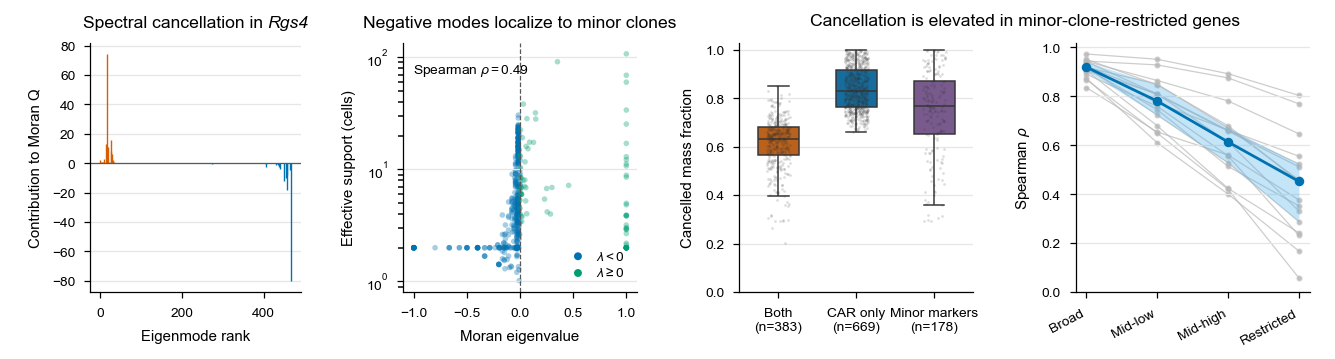

In [38]:
fig = manuscript_figure(40)
outer = fig.add_gridspec(
    1,
    1,
    left=0.055,
    right=0.985,
    bottom=0.08,
    top=0.96,
)
draw_gene_examples(fig, outer[0])
preview_figure(fig, "Lineage: Moran cancellation")

### Preview and save the combined lineage figure


Combined lineage Figure 3


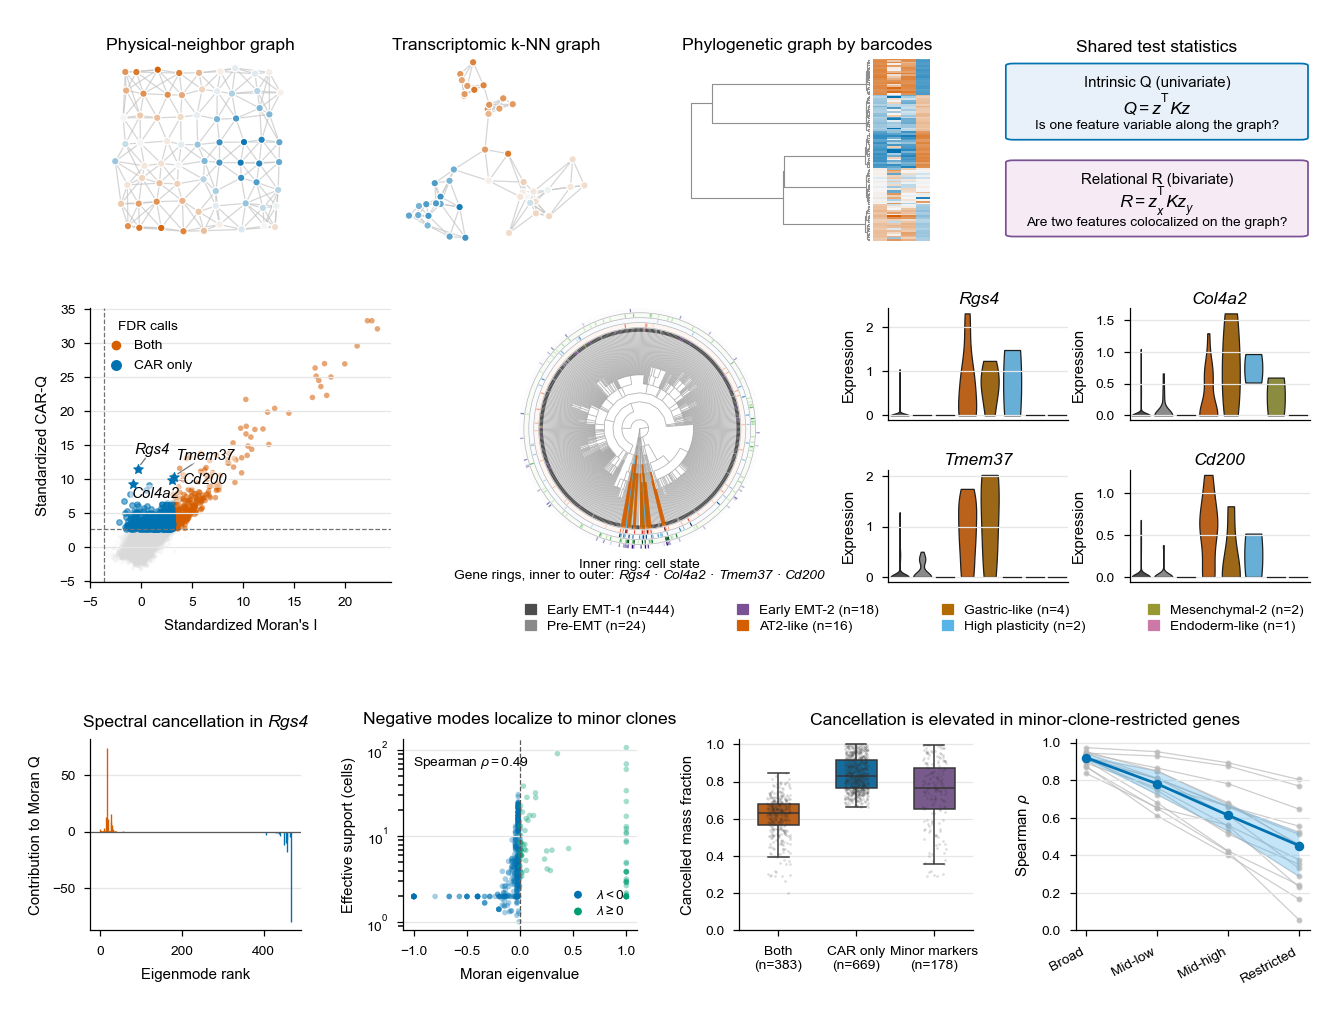

In [39]:
def build_lineage_main_figure() -> plt.Figure:
    height_mm = 145
    fig = manuscript_figure(height_mm)
    outer = fig.add_gridspec(
        4,
        1,
        left=0.055,
        right=0.985,
        bottom=15 / height_mm,
        top=1 - 7 / height_mm,
        height_ratios=(0.4, 0.6, 0.05, 0.42),
        hspace=0.4,
    )
    _draw_relation_concept(fig, outer[0])
    draw_gene_story(fig, outer[1])
    draw_gene_examples(fig, outer[3])
    return fig


preview_figure(build_lineage_main_figure(), "Combined lineage Figure 3")

In [40]:
save_figure(build_lineage_main_figure(), LINEAGE_MAIN_FIGURE_FILE)

main_lineage.pdf


## Supplement: additional lineage-tracing diagnostics

### Row 1: gene-level disagreement


In [41]:
def draw_lineage_supplement_gene(fig, spec):
    grid = spec.subgridspec(1, 3, width_ratios=(0.72, 1.08, 1.12), wspace=0.40)
    # Moran vs CAR correlation across tumors for genes grouped by significance calls
    ax = fig.add_subplot(grid[0])
    consistency = gene_summary.melt(
        id_vars="Tumor",
        value_vars=["Rho_Sig_Moran", "Rho_NonSig_Moran"],
        var_name="Group",
        value_name="Correlation",
    )
    consistency["Group"] = consistency["Group"].map(
        {
            "Rho_Sig_Moran": "Moran sig.\n"
            + f"({len(consistency.loc[consistency['Group'].eq('Rho_Sig_Moran')])} tumors)",
            "Rho_NonSig_Moran": "Moran non-sig.\n"
            + f"({len(consistency.loc[consistency['Group'].eq('Rho_NonSig_Moran')])} tumors)",
        }
    )
    sns.boxplot(
        data=consistency,
        x="Group",
        y="Correlation",
        hue="Group",
        palette=[BOTH_COLOR, CONSISTENT_COLOR],
        legend=False,
        width=0.5,
        linewidth=0.6,
        showfliers=False,
        ax=ax,
    )
    sns.stripplot(
        data=consistency,
        x="Group",
        y="Correlation",
        color="0.2",
        size=2.0,
        alpha=0.4,
        jitter=0.13,
        ax=ax,
    )
    ax.set(
        title="Moran–CAR agreement",
        xlabel="",
        ylabel=r"Spearman $\rho$ (Moran vs CAR)",
        ylim=(0.45, 0.96),
    )
    ax.tick_params(axis="x", rotation=20)
    _despine(ax)

    # Cross-tumor gene recovery curves for Moran vs CAR
    ax = fig.add_subplot(grid[1])
    rank_grid = np.linspace(0, 1, 240)
    recovery_curves = []
    for _, table in gene_recovery.groupby("Tumor", sort=False):
        table = table.sort_values("Rank_fraction")
        curve = np.interp(rank_grid, table["Rank_fraction"], table["Recovered_fraction"])
        recovery_curves.append(curve)
        if table["Tumor"].eq("3430_NT_T2").any():
            ax.plot(
                rank_grid, curve, color="darkred", lw=0.9, alpha=0.75, zorder=4, label="3430_NT_T2"
            )
        else:
            ax.plot(rank_grid, curve, color="0.72", lw=0.45, alpha=0.5, zorder=1)

    recovery_curves = np.asarray(recovery_curves)
    q1, median, q3 = np.quantile(recovery_curves, (0.25, 0.5, 0.75), axis=0)
    ax.fill_between(rank_grid, q1, q3, color="#9ECAE1", alpha=0.55, linewidth=0, zorder=2)
    ax.plot(
        rank_grid,
        median,
        color=CAR_ONLY_COLOR,
        lw=1.1,
        zorder=3,
        label=f"Median and IQR across {len(recovery_curves)} tumors",
    )
    ax.plot((0, 1), (0, 1), color="0.65", lw=0.5, ls="--")
    ax.legend(loc="lower right", frameon=False, fontsize=5.5, handlelength=0.8, labelspacing=0.2)
    ax.set(
        title="Ranking divergence\nvaries across tumors",
        xlabel="Rank fraction by Moran's I",
        ylabel="CAR-Q genes recovered",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    _despine(ax)

    # Per-gene sparsity vs negative Moran mass fraction for 3430_NT_T2
    ax = fig.add_subplot(grid[2])
    balance = gene_cancellation.assign(
        Negative_mass_fraction=lambda table: (
            table["Negative_contribution"]
            / (table["Positive_contribution"] + table["Negative_contribution"])
        )
    )
    balance["Sparsity_bin"] = pd.qcut(balance["Sparsity"], 10, duplicates="drop")
    trend = (
        balance.groupby("Sparsity_bin", observed=True)
        .agg(
            x=("Sparsity", "median"),
            y=("Negative_mass_fraction", "median"),
            q1=("Negative_mass_fraction", lambda values: values.quantile(0.25)),
            q3=("Negative_mass_fraction", lambda values: values.quantile(0.75)),
        )
        .reset_index(drop=True)
    )
    ax.fill_between(trend["x"], trend["q1"], trend["q3"], color="#9ECAE1", alpha=0.45, linewidth=0)
    ax.plot(trend["x"], trend["y"], color=CAR_ONLY_COLOR, marker="o", ms=2.6, lw=0.9)
    ax.axhline(0.5, color="0.35", lw=0.6, ls="--")
    rho = balance[["Sparsity", "Negative_mass_fraction"]].corr(method="spearman").iloc[0, 1]
    ax.text(
        0.04,
        0.96,
        rf"$\rho={rho:.2f}$, n={len(balance):,}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=5.5,
    )
    ax.text(
        0.04,
        0.502,
        "Equal positive/negative mass",
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="bottom",
        fontsize=5.5,
        color="0.30",
    )
    ax.set(
        title="Sparse genes load more negative\nMoran modes in 3430_NT_T2",
        xlabel="Fraction of zero counts",
        ylabel="Negative share of Moran mass",
        xlim=(0, 1),
        ylim=(0.36, 0.57),
    )
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    _despine(ax)

Lineage supplement: gene disagreement


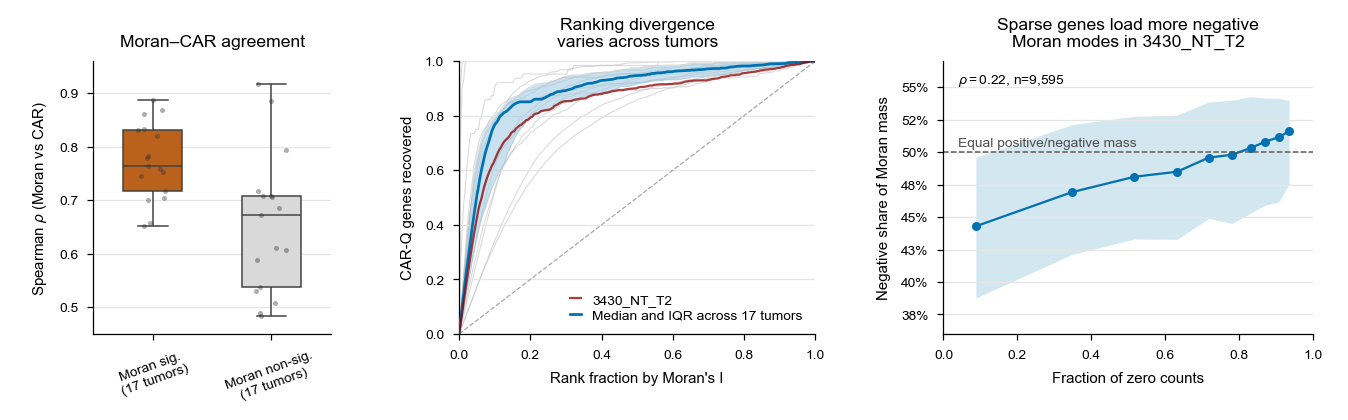

In [42]:
fig = manuscript_figure(52)
grid = fig.add_gridspec(1, 1, left=0.055, right=0.985, bottom=0.18, top=0.92)
draw_lineage_supplement_gene(fig, grid[0])
preview_figure(fig, "Lineage supplement: gene disagreement")

### Row 2: relational R diagnostics


In [43]:
def draw_bivariate_story(fig, spec):
    groups = spec.subgridspec(1, 3, width_ratios=(0.9, 2.15, 1), wspace=0.4)
    spectral_grid = groups[1].subgridspec(1, 2, wspace=0.33)
    grid = (groups[0], spectral_grid[0], spectral_grid[1], groups[2])
    # Scatter plot of Moran vs CAR scores for gene pairs
    ax = fig.add_subplot(grid[0])
    styles = (
        ("Consistent", "Within trend", CONSISTENT_COLOR, 1.5, 0.10),
        ("Moran dominant", "CAR below trend", MORAN_COLOR, 5, 0.5),
        ("CAR dominant", "CAR above trend", CAR_COLOR, 5, 0.5),
    )
    for group, label, color, size, alpha in styles:
        table = bivariate_pairs[bivariate_pairs["Group"].eq(group)]
        ax.scatter(
            table["Z_Moran"],
            table["Z_CAR"],
            s=size,
            color=color,
            alpha=alpha,
            edgecolor="none",
            rasterized=True,
            label=label,
        )

    # Add the regression line for the bivariate pairs
    slope, intercept, _ = bivariate_regression
    limits = np.asarray((bivariate_pairs["Z_Moran"].min(), bivariate_pairs["Z_Moran"].max()))
    ax.plot(limits, intercept + slope * limits, color="0.15", ls="--", lw=0.7)
    pair_names = tuple(sorted(PAIR_GENES))
    selected_pair = bivariate_pairs[
        bivariate_pairs["Gene_1"].eq(pair_names[0]) & bivariate_pairs["Gene_2"].eq(pair_names[1])
    ].iloc[0]
    ax.scatter(
        selected_pair.Z_Moran,
        selected_pair.Z_CAR,
        marker="*",
        s=40,
        color="black",
        edgecolor="white",
        linewidth=0.5,
        zorder=4,
    )
    ax.annotate(
        f"{PAIR_GENES[0]}-{PAIR_GENES[1]}",
        (selected_pair.Z_Moran, selected_pair.Z_CAR),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=6.0,
        fontstyle="italic",
        color=CAR_COLOR,
        bbox={"boxstyle": "round,pad=0.1", "fc": "white", "ec": "none", "alpha": 0.8},
    )
    n_outliers = bivariate_pairs["Group"].ne("Consistent").sum()
    ax.text(
        0.03,
        0.97,
        rf"{n_outliers:,} residual outliers (>3$\sigma$)"
        + f"\namong {len(bivariate_pairs):,} total pairs",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=5.5,
        bbox={"fc": "white", "ec": "none", "alpha": 0.8, "pad": 1},
    )
    ax.set(
        title="Moran–CAR disagreement",
        xlabel="Standardized Moran-R",
        ylabel="Standardized CAR-R",
    )
    ax.legend(
        frameon=False,
        loc="lower right",
        title="3730_NT_T2",
        title_fontsize=5.5,
        handletextpad=0.3,
        labelspacing=0.2,
    )
    _despine(ax)

    # Show how the selected pair occupies opposing signed Moran modes.
    ax = fig.add_subplot(grid[1])
    coefficients = spectral["coefficients"]
    eigenvalues = spectral["eigenvalues"]
    selected_modes = spectral["selected_modes"].astype(int)
    eigenvalue_cmap = paper_diverging_cmap("lineage_eigenvalues")
    scatter = ax.scatter(
        coefficients[:, 0],
        coefficients[:, 1],
        c=eigenvalues,
        cmap=eigenvalue_cmap,
        s=4,
        alpha=0.55,
        edgecolor="none",
        rasterized=True,
    )
    for mode, color in zip(selected_modes, (POSITIVE_MODE_COLOR, NEGATIVE_MODE_COLOR), strict=True):
        ax.scatter(
            coefficients[mode, 0],
            coefficients[mode, 1],
            s=28,
            facecolor="none",
            edgecolor=color,
            linewidth=0.8,
        )
    ax.axhline(0, color="0.7", lw=0.5)
    ax.axvline(0, color="0.7", lw=0.5)
    ax.set(
        xlabel=rf"$\mathit{{{PAIR_GENES[0]}}}$ coefficient",
        ylabel=rf"$\mathit{{{PAIR_GENES[1]}}}$ coefficient",
    )
    ax.set_title(
        rf"Spectral cancellation in $\mathit{{{PAIR_GENES[0]}}}$"
        rf"–$\mathit{{{PAIR_GENES[1]}}}$",
        ha="left",
        x=0.0,
    )
    cax = ax.inset_axes((0.82, 0.07, 0.04, 0.28))
    colorbar = fig.colorbar(scatter, cax=cax, ticks=(eigenvalues.min(), 0, eigenvalues.max()))
    colorbar.ax.tick_params(labelsize=5.5, length=1.5, pad=1)
    colorbar.ax.set_title(r"$\lambda_i$", fontsize=5.5, pad=1)
    _despine(ax)

    # Plot the contributions of eigenmodes to the Moran R statistic for the selected gene pair
    ax = fig.add_subplot(grid[2])
    contributions = spectral["contributions"]
    colors = eigenvalue_cmap(
        mpl.colors.Normalize(eigenvalues.min(), eigenvalues.max())(eigenvalues)
    )
    ax.vlines(np.arange(len(contributions)), 0, contributions, color=colors, lw=0.5)
    for mode, color, label in zip(
        selected_modes,
        (POSITIVE_MODE_COLOR, NEGATIVE_MODE_COLOR),
        ("Mode-P1", "Mode-N1"),
        strict=True,
    ):
        ax.scatter(mode, contributions[mode], s=13, color=color, zorder=3)
        ax.text(
            mode,
            contributions[mode],
            label,
            color=color,
            fontsize=6.0,
            ha="left" if contributions[mode] > 0 else "right",
            va="bottom" if contributions[mode] > 0 else "top",
        )
    ax.axhline(0, color="0.4", lw=0.5)
    ax.set(xlabel="Eigenmode index", ylabel="Contribution to Moran R")
    _despine(ax)

    # Plot the radial tree of 3730_NT_T2 with the selected modes and gene pair expression tracks
    ax = fig.add_subplot(grid[3])
    cells = spectral["cells"].astype(str)
    mode_vectors = np.asarray(spectral["selected_vectors"])
    expression = np.asarray(spectral["pair_expression"])
    tracks = [
        (
            f"mode {selected_modes[0]}",
            pd.Series(mode_vectors[:, 0], index=cells),
            paper_diverging_cmap("lineage_mode_positive"),
        ),
        (
            f"mode {selected_modes[1]}",
            pd.Series(mode_vectors[:, 1], index=cells),
            paper_diverging_cmap("lineage_mode_negative"),
        ),
        (PAIR_GENES[0], pd.Series(expression[:, 0], index=cells), "Greens"),
        (PAIR_GENES[1], pd.Series(expression[:, 1], index=cells), "Purples"),
    ]
    dominant_mode = np.abs(mode_vectors).argmax(axis=1)
    strength = np.abs(mode_vectors).max(axis=1)
    nonzero_strength = strength[strength > 0]
    strength /= np.quantile(nonzero_strength, 0.95)
    strength = np.clip(strength, 0, 1)
    mode_colors = (POSITIVE_MODE_COLOR, NEGATIVE_MODE_COLOR)
    branch_colors = pd.Series(
        [
            mcolors.to_rgba(mode_colors[index], 0 if value < 0.15 else 0.2 + 0.8 * value)
            for index, value in zip(dominant_mode, strength, strict=True)
        ],
        index=cells,
    )
    _draw_radial_tree(
        ax,
        "3730_NT_T2",
        tracks,
        "",
        show_track_note=False,
        terminal_branch_colors=branch_colors,
    )
    boundary_colors = (
        PAPER_COLORS["cool"],
        PAPER_COLORS["green"],
        PAPER_COLORS["purple"],
    )
    for index, color in enumerate(boundary_colors, start=1):
        radius = 1.0 + 0.05 * (index - 0.5)
        ax.add_patch(
            mpl.patches.Circle(
                (0, 0),
                radius,
                fill=False,
                edgecolor="white",
                linewidth=1.2,
                zorder=4,
            )
        )
        ax.add_patch(
            mpl.patches.Circle(
                (0, 0),
                radius,
                fill=False,
                edgecolor=color,
                linewidth=0.35,
                zorder=5,
            )
        )
    ax.text(
        0.5,
        -0.03,
        "Branches: P1 (red) or N1 (blue)",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=5.5,
    )
    add_gene_label(
        ax,
        "Rings: P1 · N1  |  ",
        PAIR_GENES,
        xy=(0.5, -0.13),
        fontsize=5.5,
        loc="upper center",
    )
    ax.set_anchor("N")

Lineage: relational diagnostics


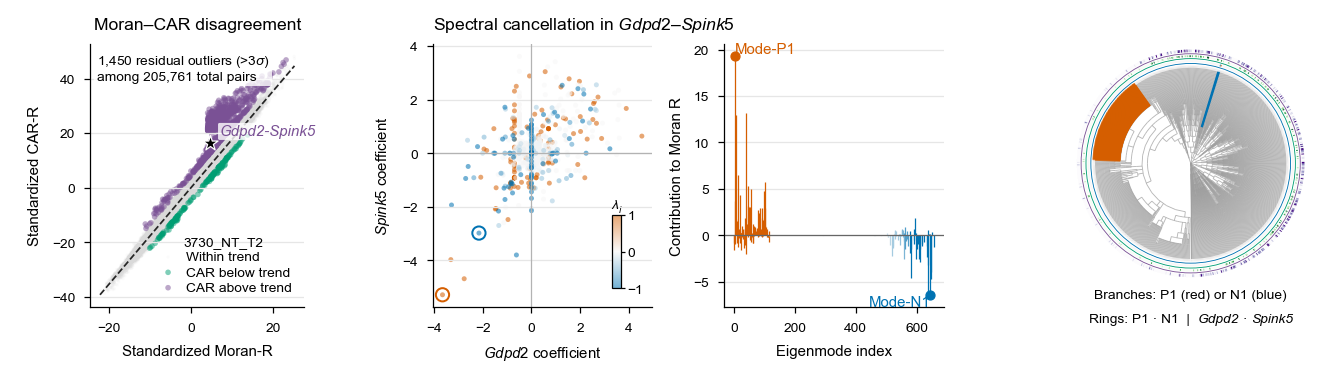

In [44]:
fig = manuscript_figure(50)
grid = fig.add_gridspec(1, 1, left=0.055, right=0.985, bottom=0.18, top=0.92)
draw_bivariate_story(fig, grid[0])
preview_figure(fig, "Lineage: relational diagnostics")

### Row 3: bivariate R-statistic consequences


In [45]:
def draw_lineage_supplement_bottom(fig, spec):
    grid = spec.subgridspec(1, 3, width_ratios=(0.8, 1, 1), wspace=0.4)
    moran_linkage = linkage(bivariate_moran, method="ward")
    car_linkage = linkage(bivariate_car, method="ward")

    # Number of discordant gene pairs across outlier thresholds
    ax = fig.add_subplot(grid[0])
    summary = bivariate_summary[bivariate_summary["Sigma"].le(5)].copy()
    summary["Group"] = summary["Group"].map(
        {"Moran dominant": "CAR below trend", "CAR dominant": "CAR above trend"}
    )
    palette = {"CAR below trend": MORAN_COLOR, "CAR above trend": CAR_COLOR}
    sns.boxplot(
        data=summary,
        x="Sigma",
        y="Proportion",
        hue="Group",
        palette=palette,
        showfliers=False,
        linewidth=0.6,
        gap=0.08,
        ax=ax,
    )
    ax.set(
        xlabel=r"Residual threshold ($\sigma$)",
        ylabel="Proportion of gene pairs",
    )
    ax.set_title("Discordance across residual thresholds", ha="left", x=0.0)
    ax.legend(frameon=False, loc="upper right", title="Relative to trend", title_fontsize=5.5)
    _despine(ax)

    # Heatmap of Moran vs CAR scores for 3730_NT_T2 genes
    ax = fig.add_subplot(grid[1])
    ordering = leaves_list(car_linkage)
    moran, car = bivariate_moran, bivariate_car
    moran, car = moran[np.ix_(ordering, ordering)], car[np.ix_(ordering, ordering)]
    limit_m, limit_c = np.percentile(np.abs(moran), 98), np.percentile(np.abs(car), 98)
    moran_image = ax.imshow(
        np.ma.masked_array(moran, mask=np.triu(np.ones_like(moran, dtype=bool))),
        cmap="RdBu_r",
        vmin=-limit_m,
        vmax=limit_m,
        interpolation="nearest",
        rasterized=True,
    )
    car_image = ax.imshow(
        np.ma.masked_array(car, mask=np.tril(np.ones_like(car, dtype=bool))),
        cmap="PuOr_r",
        vmin=-limit_c,
        vmax=limit_c,
        interpolation="nearest",
        rasterized=True,
    )
    ax.plot((0, len(moran)), (0, len(moran)), color="0.15", lw=0.5)
    ax.set(
        title="Coexpression structure",
        xlabel=f"{len(moran)} genes (CAR order)",
        ylabel="Genes (CAR order)",
        xticks=[],
        yticks=[],
    )
    for label, xy, ha, va in (
        ("Moran-R", (0.03, 0.04), "left", "bottom"),
        ("CAR-R", (0.97, 0.96), "right", "top"),
    ):
        ax.text(
            *xy,
            label,
            transform=ax.transAxes,
            ha=ha,
            va=va,
            fontsize=5.5,
            bbox={"fc": "white", "ec": "none", "alpha": 0.85, "pad": 1},
        )
    for image, limit, label, bottom in (
        (moran_image, limit_m, "Moran-R", 0.57),
        (car_image, limit_c, "CAR-R", 0.07),
    ):
        cax = ax.inset_axes((1.14, bottom, 0.035, 0.32))
        colorbar = fig.colorbar(image, cax=cax, ticks=(-limit, 0, limit), format="%.0f")
        colorbar.ax.tick_params(labelsize=5, length=1.5, pad=1)
        colorbar.ax.set_title(label, fontsize=5, pad=2)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Match six Ward modules across kernels and summarize reassignment.
    ax = fig.add_subplot(grid[2])
    n_modules = 6
    moran_modules = fcluster(moran_linkage, n_modules, criterion="maxclust") - 1
    car_modules = fcluster(car_linkage, n_modules, criterion="maxclust") - 1
    counts = np.zeros((n_modules, n_modules), dtype=int)
    np.add.at(counts, (moran_modules, car_modules), 1)
    rows, columns = linear_sum_assignment(-counts)
    counts = counts[:, columns[np.argsort(rows)]]
    fractions = counts / counts.sum(axis=1, keepdims=True)
    retained = np.trace(counts) / counts.sum()
    ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    for row, column in np.argwhere(fractions >= 0.08):
        value = fractions[row, column]
        ax.text(
            column,
            row,
            f"{value:.0%}",
            ha="center",
            va="center",
            fontsize=5.5,
            color="white" if value > 0.55 else "0.15",
        )
    ticks = np.arange(n_modules)
    ax.set(
        title=f"{retained:.0%} matched module assignments",
        xlabel="CAR-based module",
        ylabel="Moran-based module",
        xticks=ticks,
        yticks=ticks,
        xticklabels=ticks + 1,
        yticklabels=ticks + 1,
    )
    ax.tick_params(length=0)

Lineage supplement: relational consequences


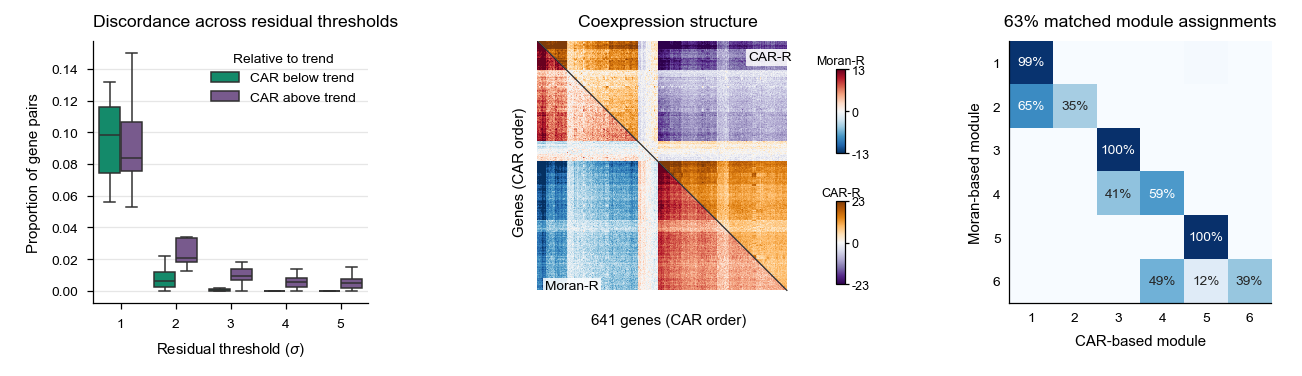

In [46]:
fig = manuscript_figure(50)
grid = fig.add_gridspec(1, 1, left=0.055, right=0.985, bottom=0.18, top=0.92)
draw_lineage_supplement_bottom(fig, grid[0])
preview_figure(fig, "Lineage supplement: relational consequences")

### Preview and save the combined lineage supplement


Combined lineage supplement


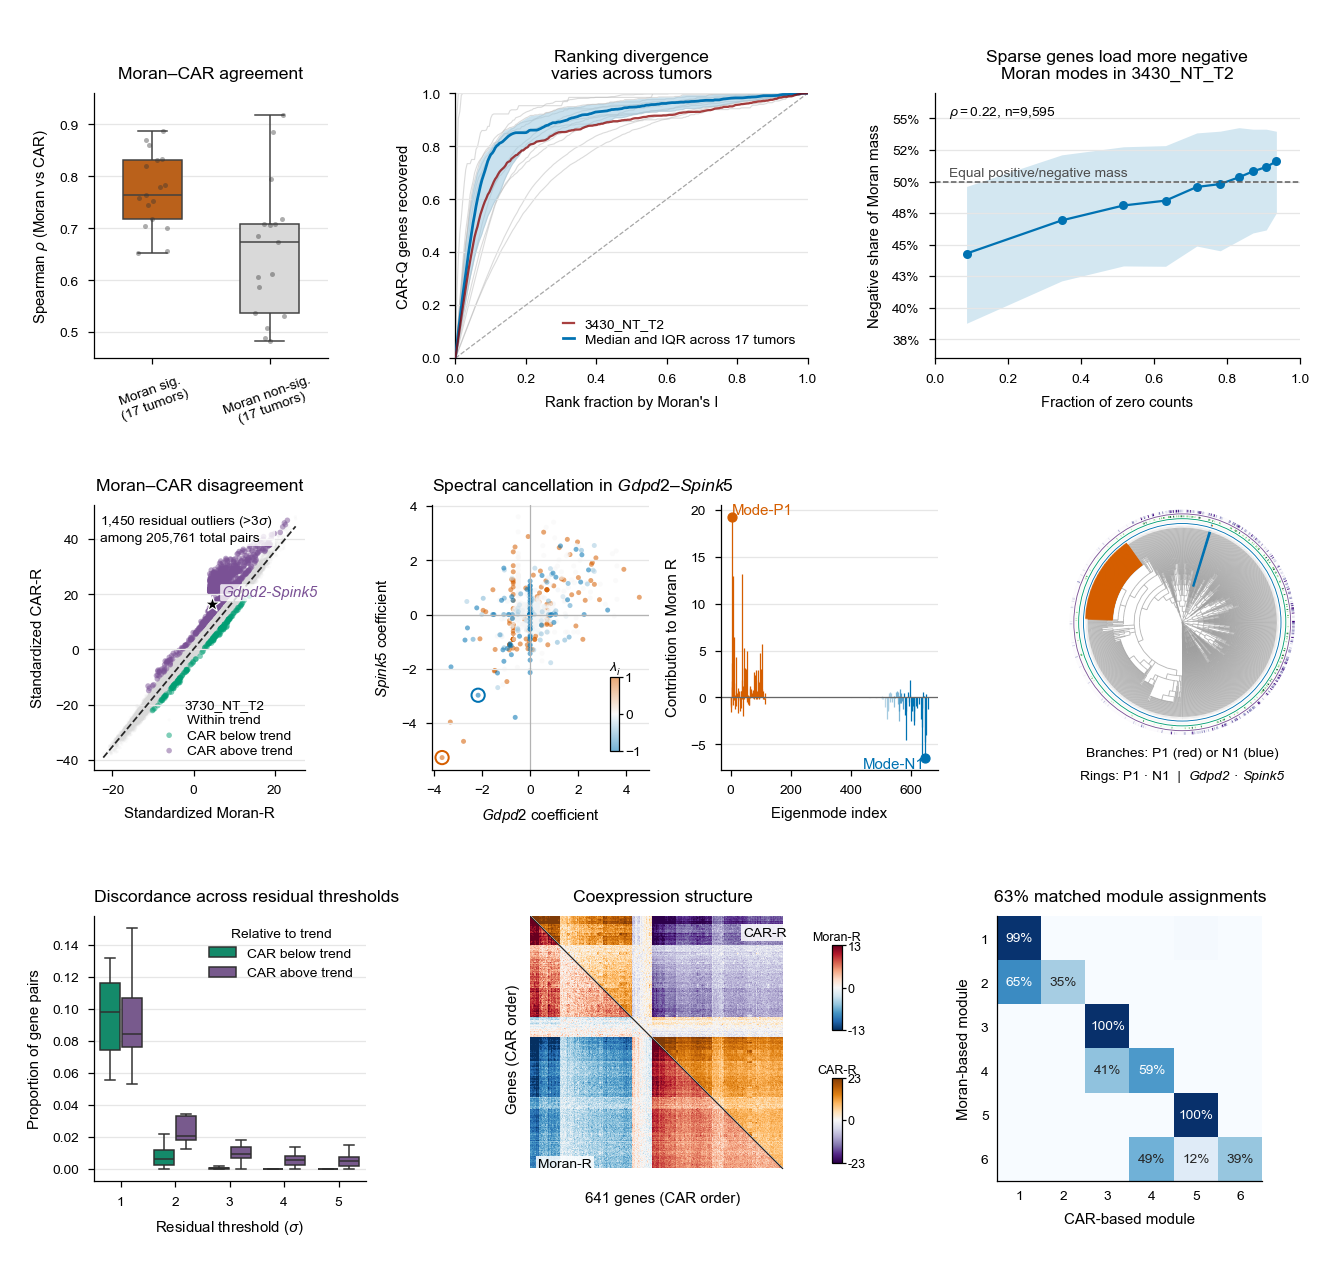

In [47]:
def build_lineage_supplementary_figure() -> plt.Figure:
    height_mm = 175
    fig = manuscript_figure(height_mm)
    outer = fig.add_gridspec(
        5,
        1,
        left=0.055,
        right=0.975,
        bottom=11.5 / height_mm,
        top=1 - 10 / height_mm,
        height_ratios=(0.9, 0.05, 0.9, 0.05, 0.9),
        hspace=0.4,
    )
    draw_lineage_supplement_gene(fig, outer[0])
    draw_bivariate_story(fig, outer[2])
    draw_lineage_supplement_bottom(fig, outer[4])
    return fig


preview_figure(build_lineage_supplementary_figure(), "Combined lineage supplement")

In [48]:
save_figure(build_lineage_supplementary_figure(), LINEAGE_SUPPLEMENTARY_FIGURE_FILE)

supp_lineage.pdf
